# Imports & functions

In [1]:
import glob
import inspect
import math
import os
import random
import re
from re import match
from collections import deque
from functools import partial
from itertools import cycle
from typing import Dict, Optional, Union

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.spatial.distance as sp_dist
import scipy.stats
import seaborn as sns
import shap
import sklearn
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    make_scorer,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

import samnet as st
from samnet.metrics import *
from samnet.sampling import *

/home/llober/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def calculate_dispersion_distance(df):

    mean_dist = []
    var_dist = []
    methods = []
    graphs = []
    sizes = []

    #doesn't count the original net
    for method in df['sampling_method'].unique()[1:]: 
        swp = df.loc[df['sampling_method'] == method]
        for size in swp['sample_size'].unique():
            swp2 = swp.loc[swp['sample_size'] == size]
            for graph in swp2['graph_id'].unique():    
                pca_1 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_1'].values
                pca_2 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_2'].values
                pca_3 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_2'].values

                #original data: extracts it and then repeats n=len(pca_1) times
                orig_pca_1 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_1'].values[0], len(pca_1))
                orig_pca_2 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_2'].values[0], len(pca_2))
                orig_pca_3 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_3'].values[0], len(pca_3))

                #perform the calculation d = sqrt( sum_i( (ci_orig - ci_sample)^2 ) )

                distance = np.sqrt( np.pow(pca_1 - orig_pca_1, 2) + np.pow(pca_2 - orig_pca_2, 2) + np.pow(pca_3 - orig_pca_3, 2) )
                mean_dist.append(np.mean(distance))
                var_dist.append(np.var(distance))

                #save names for the dataframe
                methods.append(method)
                graphs.append(graph)
                sizes.append(size)

    res = pd.DataFrame(data={'method': methods, 'graph_ID': graphs, 'sample_size':sizes, 'mean': mean_dist, 'var': var_dist})

    return res

In [3]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [ ]:
path = '/your/path/'    #path to PCA files

# Powergrid network

## Sampling and metrics computation

In [6]:
graph_list = [nx.read_edgelist("data/nets/powergrid.txt")]
pg_len = len(graph_list[0])
print(pg_len)

4941


In [7]:
len(graph_list[0].edges())

6594

Here we need the following sizes: 5%, 10%, 25%, 40%, 50% and 75%, so:


In [4]:
sizes_pg = [int(pg_len*0.05),int(pg_len*0.1),int(pg_len*0.25),
            int(pg_len*0.4),int(pg_len*0.5),int(pg_len*0.75)]

och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=sizes_pg, runs=50)

Sampling graphs: 100%|██████████| 2100/2100 [00:11<00:00, 182.01it/s]


In [5]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [12]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 14/14 (transitivity): 100%|██████████| 2101/2101 [00:01<00:00, 1051.38it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,4941,6594,0.000540,0.003457,18.989185,0.003642,0.000291,0.000051,...,7.920812e-15,0.0,6.082763,2.253223,2.253223,5.338191,13.307590,34.924118,3.137455,0.103153
1,0,snowball,247,339,0.011158,-0.213211,5.471479,0.018251,0.002402,0.000552,...,3.516771e-09,0.0,5.656854,2.230467,2.230467,5.489879,14.849428,43.879296,3.415183,0.126493
2,0,snowball,247,275,0.009052,-0.312078,8.726704,0.031538,0.005098,0.001223,...,1.684790e-09,0.0,4.358899,2.043823,2.043823,4.453441,10.283087,25.070006,2.966815,0.013825
3,0,snowball,247,283,0.009315,-0.263582,6.873671,0.023974,0.003526,0.000940,...,3.296434e-09,0.0,4.795832,2.062838,2.062838,4.582996,10.991404,28.513367,2.985273,0.014670
4,0,snowball,247,311,0.010237,-0.253058,8.095454,0.028961,0.005512,0.001958,...,1.812218e-09,0.0,4.582576,2.172394,2.172394,5.036437,12.362681,31.971348,3.195153,0.114055
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,0,frontier_sampling,3705,5013,0.000731,0.034117,18.465720,0.004717,0.000366,0.000058,...,2.276699e-14,0.0,5.744563,2.270251,2.270251,5.412146,13.562574,35.754706,3.135498,0.115655
2097,0,frontier_sampling,3705,5004,0.000729,0.024798,18.519044,0.004731,0.000395,0.000068,...,2.305001e-14,0.0,5.744563,2.268469,2.268469,5.402429,13.520347,35.584418,3.132601,0.111257
2098,0,frontier_sampling,3705,4909,0.000715,-0.081493,18.437735,0.004709,0.000407,0.000073,...,2.457056e-14,0.0,6.000000,2.248673,2.248673,5.299865,13.096788,33.946681,3.096574,0.086139
2099,0,frontier_sampling,3705,5002,0.000729,0.055410,18.949828,0.004847,0.000406,0.000073,...,2.143790e-14,0.0,5.744563,2.267793,2.267793,5.400270,13.515836,35.575995,3.132503,0.121197


In [13]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/real_net_sampling/swp/', output_filename='combined_metrics_pg.csv'
)

Successfully combined 14 files into 'data/real_net_sampling/swp/combined_metrics_pg.csv' (2101 rows, 53 columns).


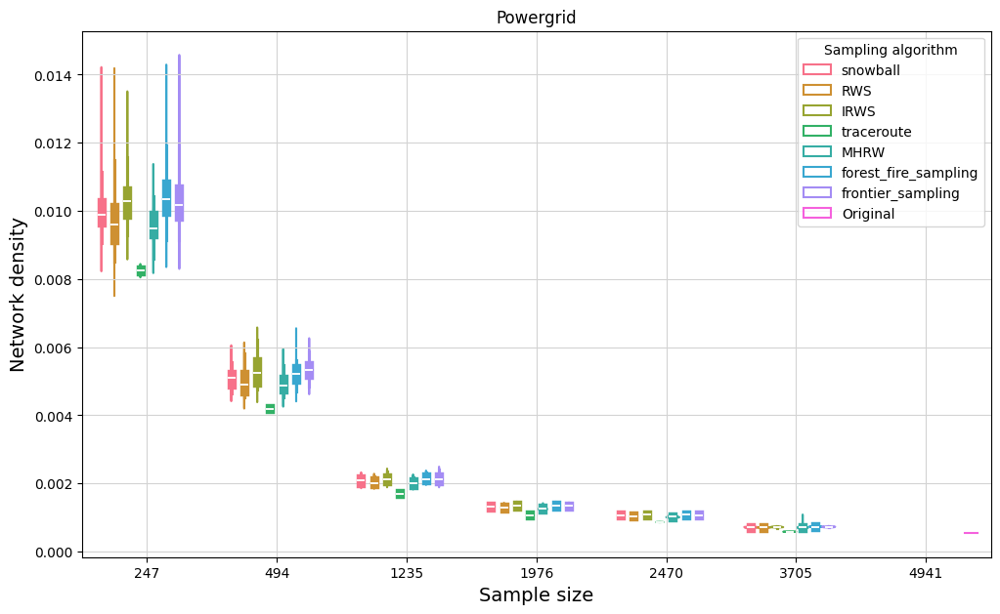

In [14]:
df_test = pd.read_csv('data/real_net_sampling/combined_metrics_pg.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.violinplot(df_test, x='sample_size', y='net_density', hue='sampling_method', fill=False, ax=ax, palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Powergrid')
plt.legend(title='Sampling algorithm')

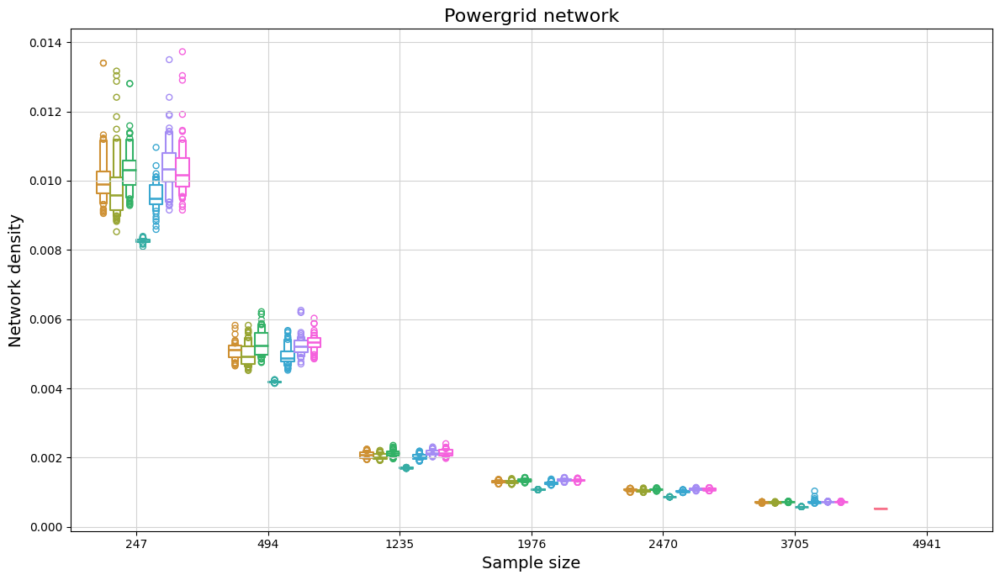

In [15]:
#No legends
df_test = pd.read_csv('data/real_net_sampling/combined_metrics_pg.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Powergrid network', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_pg.pdf', format='pdf')
plt.show()

## PCA

In [16]:
df = pd.read_csv('data/real_net_sampling/combined_metrics_pg.csv')

In [17]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 53.3%
PCA Component 2 EVR: 28.1%
PCA Component 3 EVR: 6.2%


In [18]:
df_pca.to_csv('data/pca/pca_pg.csv')

In [131]:
df_pca = pd.read_csv('data/pca/pca_pg.csv')

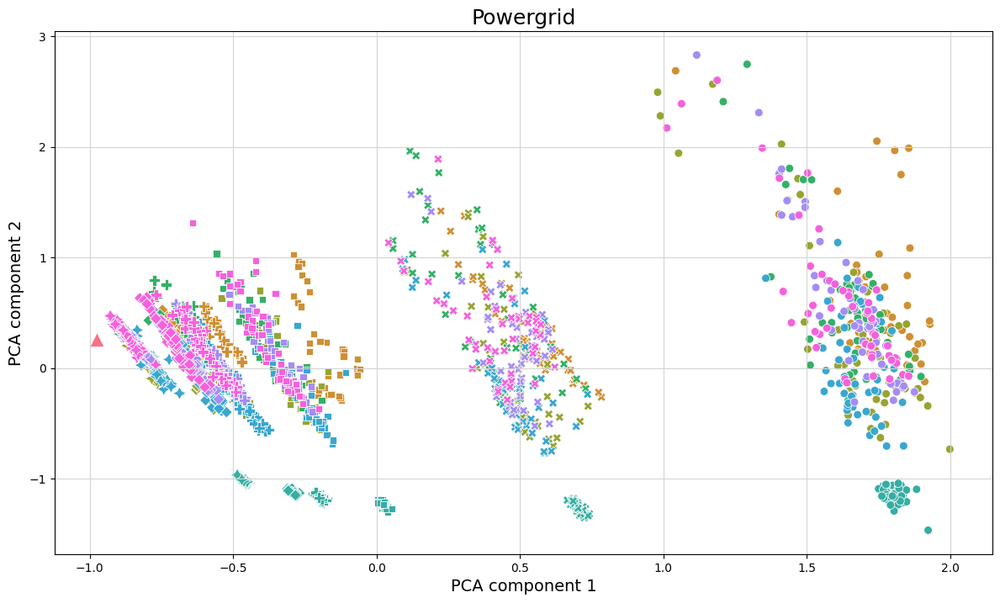

In [20]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Powergrid', fontsize=18)
plt.savefig('PCA_pg.pdf', format='pdf')
plt.show()

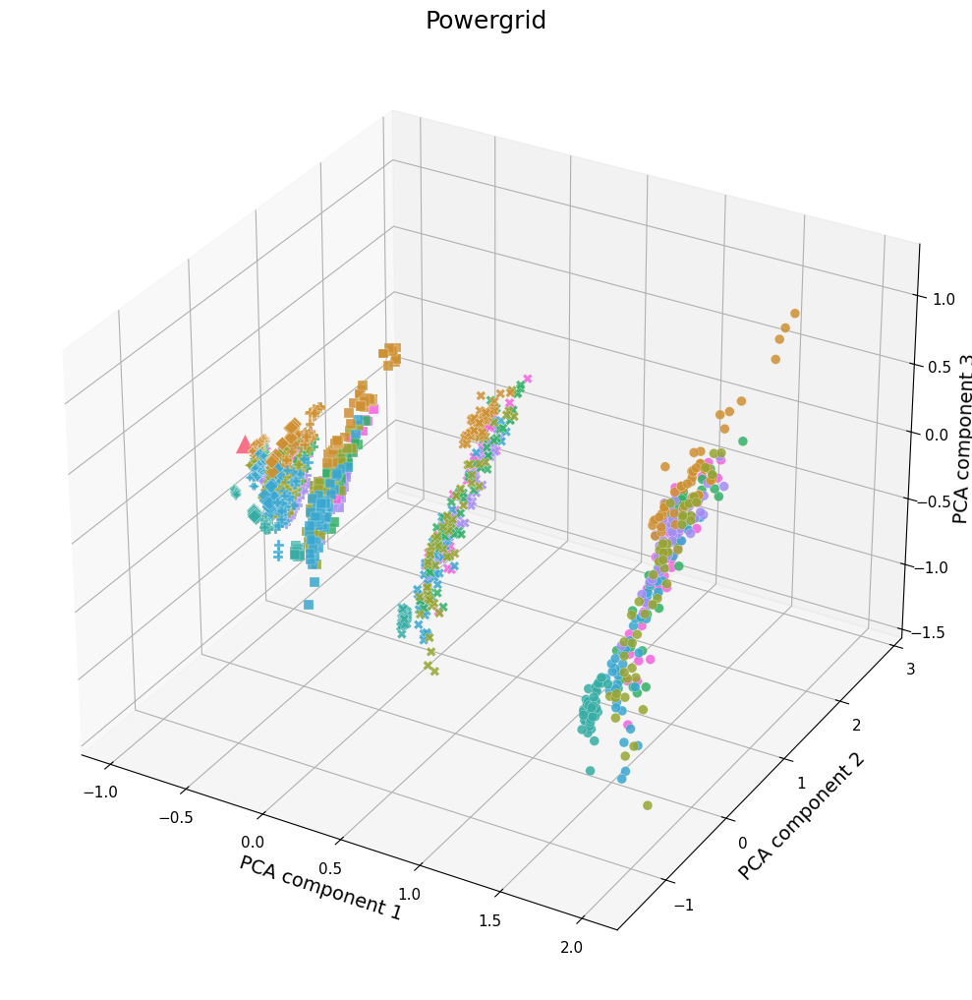

In [132]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Powergrid', fontsize=18)
plt.savefig('PCA_pg_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

## ML

In [ ]:
#Data handling - run only once!

#Load tables
path = '/your/path/'
data_ba = pd.read_csv(path + 'pca_ba.csv', index_col=0)
data_nlba = pd.read_csv(path + 'pca_nlba.csv', index_col=0)
data_er = pd.read_csv(path + 'pca_er.csv', index_col=0)
data_ws = pd.read_csv(path + 'pca_ws.csv', index_col=0)

#Add an extra column that'll be our target variable 
data_ba['graph_type'] = np.repeat('BA', len(data_ba))
data_er['graph_type'] = np.repeat('ER', len(data_er))
data_nlba['graph_type'] = np.repeat('NLBA', len(data_nlba))
data_ws['graph_type'] = np.repeat('WS', len(data_ws))

#Concatenate everything
res = pd.concat([data_ba,data_nlba,data_er,data_ws], axis=0)
res.to_csv(path+'full_pca_synth_networks.csv')

### 40%

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == 400)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[3])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [65]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [66]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [18]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [19]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([144.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 206.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

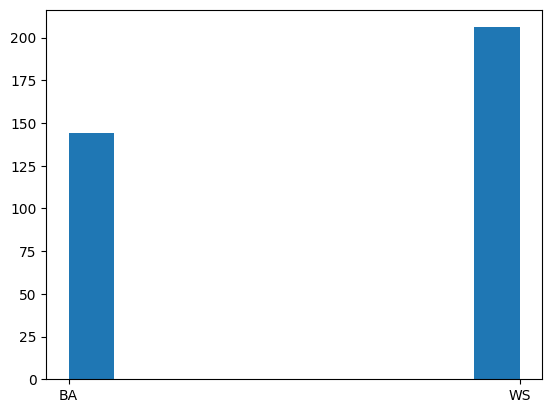

In [20]:
plt.hist(y_pred_pg)

In [28]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

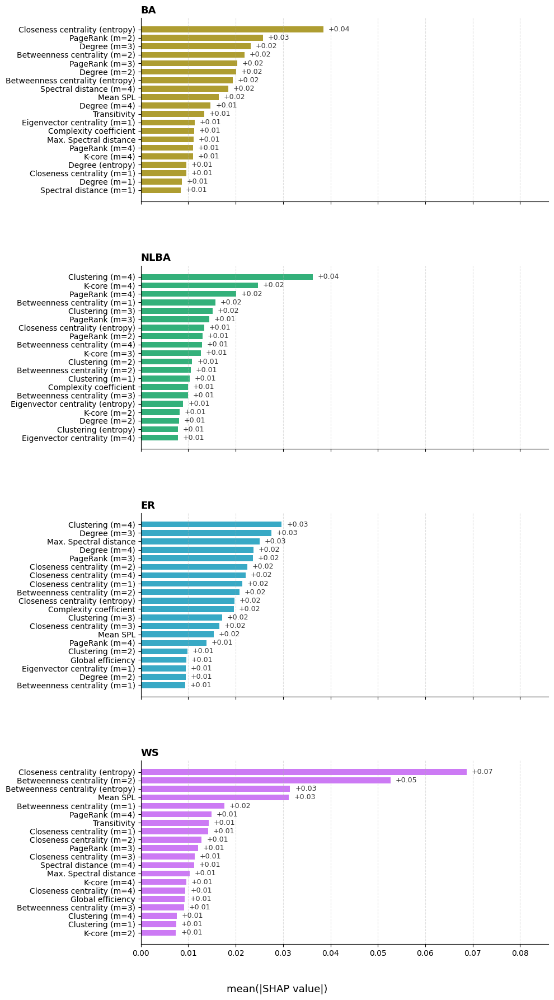

In [29]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_0.4N.pdf', format='pdf')
plt.show()

# Maier network

## Sampling and metrics computation

In [4]:
maier = nx.read_gml('data/nets/bfmaier_anonymized_fb_network.gml')
largest_cc = max(nx.connected_components(maier), key=len)
maier = maier.subgraph(largest_cc).copy()

graph_list = [maier]
maier_len = len(graph_list[0])
print(maier_len)

329


In [5]:
len(graph_list[0].edges())

1954

Here we need the following sizes: 5%, 10%, 25%, 40%, 50% and 75%, so:


In [25]:
sizes_maier = [int(maier_len*0.05),int(maier_len*0.1),int(maier_len*0.25),
            int(maier_len*0.4),int(maier_len*0.5),int(maier_len*0.75)]

och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=sizes_maier, runs=50)

Sampling graphs: 100%|██████████| 2100/2100 [00:00<00:00, 4310.86it/s]


In [26]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [27]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 14/14 (transitivity): 100%|██████████| 2101/2101 [00:00<00:00, 5418.29it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,329,1954,0.036215,0.073881,3.584217,0.007903,0.000676,0.000092,...,8.581791e-10,0.000000,11.269428,4.609668,4.609668,23.756839,133.637066,807.236149,5.657891,0.512061
1,0,snowball,16,15,0.125000,-1.000000,1.875000,0.062500,0.062500,0.062500,...,2.911647e-03,0.337290,4.242641,1.657282,1.657282,3.750000,11.269514,41.250000,0.846882,0.000000
2,0,snowball,16,17,0.141667,-0.780822,2.208333,0.086310,0.049983,0.030921,...,3.830179e-04,0.543564,4.358899,1.850980,1.850980,4.250000,11.281168,33.468750,2.527924,0.088235
3,0,snowball,16,15,0.125000,-1.000000,1.875000,0.062500,0.062500,0.062500,...,2.911647e-03,0.337290,4.242641,1.657282,1.657282,3.750000,11.269514,41.250000,0.846882,0.000000
4,0,snowball,16,15,0.125000,-1.000000,1.875000,0.062500,0.062500,0.062500,...,2.911647e-03,0.337290,4.242641,1.657282,1.657282,3.750000,11.269514,41.250000,0.846882,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,0,frontier_sampling,246,1600,0.053094,0.044221,3.203484,0.009031,0.000787,0.000103,...,1.972379e-09,0.000000,10.908712,4.889153,4.889153,26.016260,148.371219,898.712142,5.633000,0.523413
2097,0,frontier_sampling,246,1701,0.056446,0.033341,3.281931,0.009352,0.001004,0.000164,...,1.822546e-09,0.000000,10.816654,5.037140,5.037140,27.658537,162.411724,1008.549673,5.714815,0.544124
2098,0,frontier_sampling,246,1690,0.056081,0.093483,3.407267,0.009866,0.001019,0.000174,...,1.362812e-09,0.000000,10.392305,5.033074,5.033074,27.479675,159.933091,981.700575,5.667113,0.550482
2099,0,frontier_sampling,246,1693,0.056181,0.074703,3.412875,0.009889,0.000951,0.000149,...,1.455395e-09,0.000000,10.246951,5.025673,5.025673,27.528455,160.980883,993.337035,5.713084,0.554534


In [28]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/real_net_sampling/swp/', output_filename='combined_metrics_maier.csv'
)

Successfully combined 14 files into 'data/real_net_sampling/swp/combined_metrics_maier.csv' (2101 rows, 53 columns).


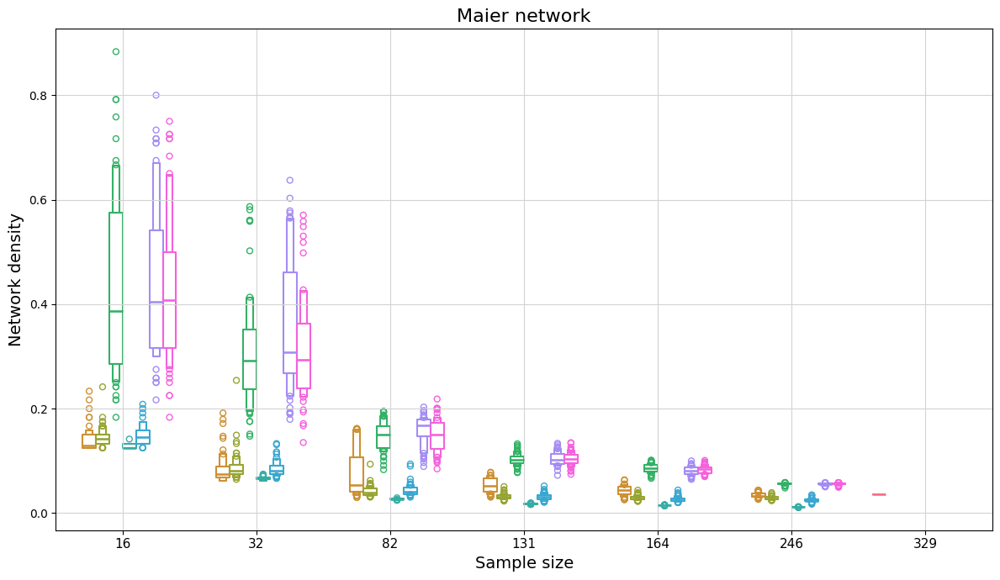

In [31]:
#No legends
df_test = pd.read_csv('data/real_net_sampling/combined_metrics_maier.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Maier network', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_maier.pdf', format='pdf')
plt.show()

## PCA

In [32]:
df = pd.read_csv('data/real_net_sampling/combined_metrics_maier.csv')

In [33]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 60.9%
PCA Component 2 EVR: 21.3%
PCA Component 3 EVR: 5.9%


In [34]:
df_pca.to_csv('data/pca/pca_maier.csv')

In [133]:
df_pca = pd.read_csv('data/pca/pca_maier.csv')

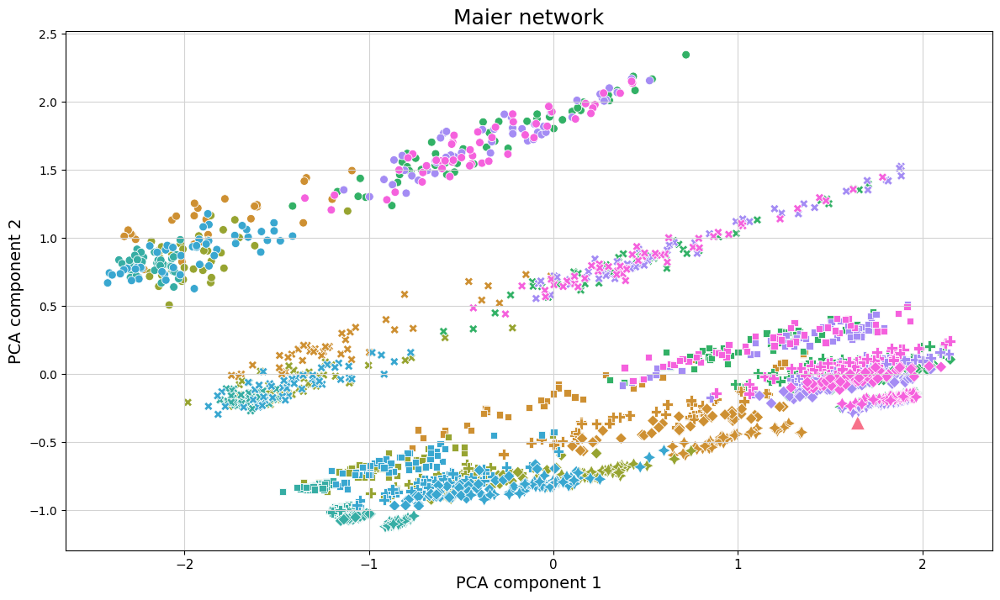

In [48]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Maier network', fontsize=18)
plt.savefig('PCA_maier.pdf', format='pdf')
plt.show()

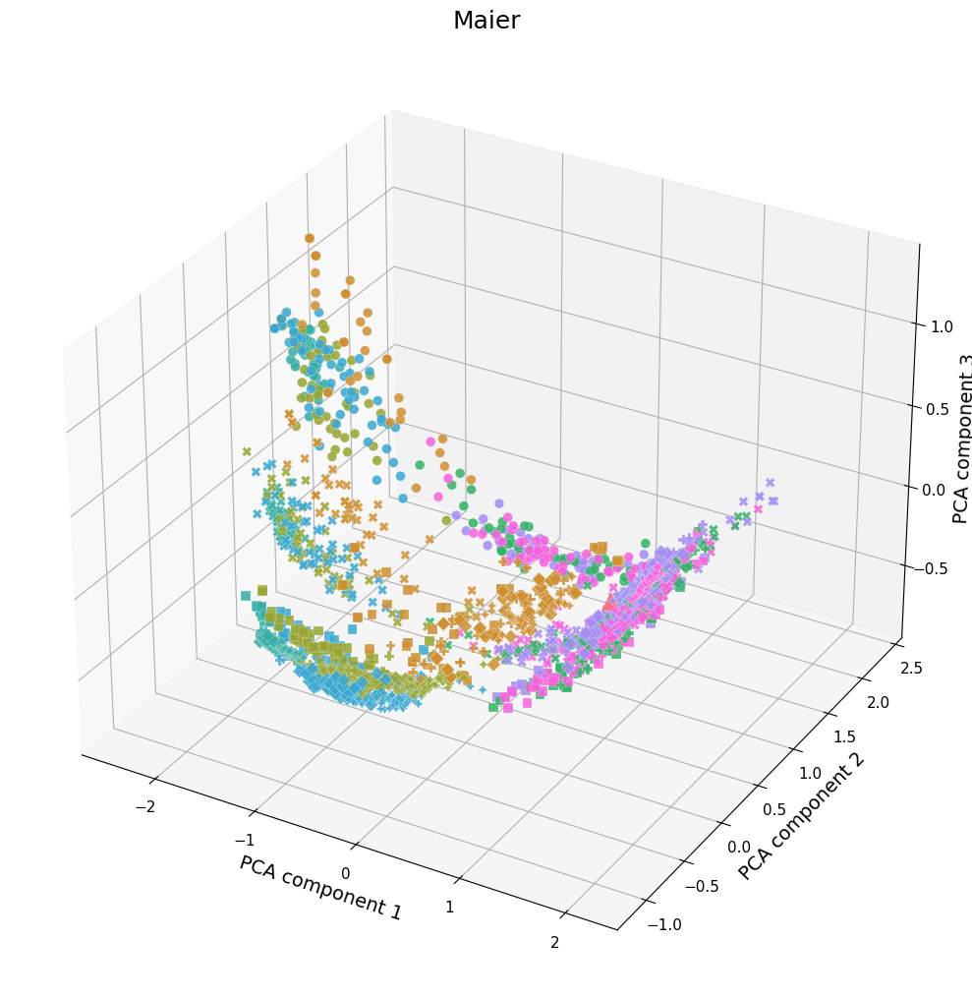

In [134]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Maier', fontsize=18)
plt.savefig('PCA_maier_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

## ML

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == 400)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[3])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [86]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [30]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [32]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 53.,   0.,   0.,   0.,   0., 152.,   0.,   0.,   0., 145.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

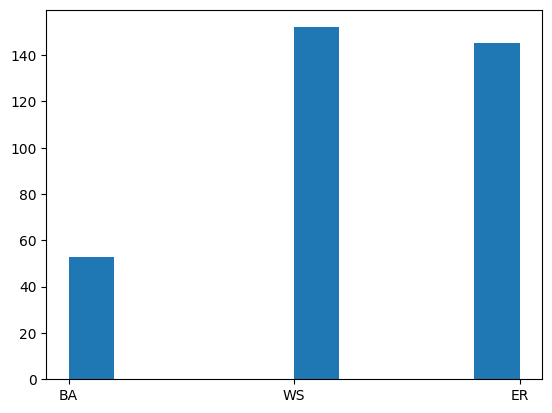

In [33]:
plt.hist(y_pred_maier)

In [34]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [35]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

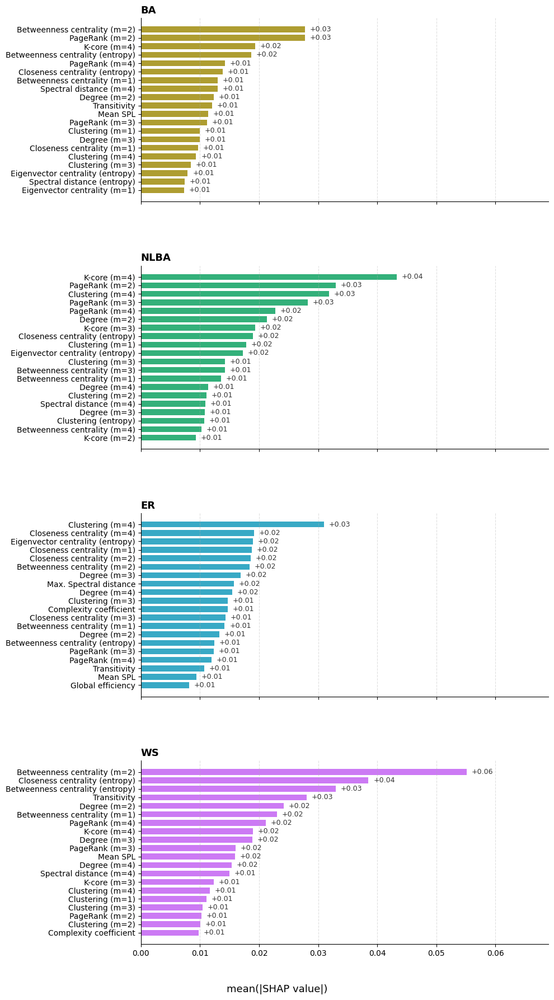

In [36]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_0.4N.pdf', format='pdf')
plt.show()

# Citation network

## Sampling and metrics computation

In [3]:
cit = nx.read_edgelist("data/nets/cit-DBLP.txt")
cit.remove_edges_from(nx.selfloop_edges(cit))
maior_componente = max(nx.connected_components(cit), key=len)
cit = cit.subgraph(maior_componente).copy()

graph_list = [cit]
cit_len = len(graph_list[0])
print(cit_len)

12495


In [7]:
len(graph_list[0].edges())

49563

Here we need the following sizes: 5%, 10%, 25%, 40%, 50% and 75%, so:


In [6]:
sizes_cit = [int(cit_len*0.05),int(cit_len*0.1),int(cit_len*0.25),
            int(cit_len*0.4),int(cit_len*0.5),int(cit_len*0.75)]

och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS,traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=sizes_cit, runs=50)

Sampling graphs: 100%|██████████| 2100/2100 [02:43<00:00, 12.81it/s] 


In [13]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

### Stages

In [ ]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 3/14 (betweenness_info):   4%|▍         | 88/2101 [24:11<6:48:25, 12.17s/it]   

In [ ]:
och.sample_describer(functions_list=func_list[3:], n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 8/11 (local_efficiency):  39%|███▊      | 812/2101 [08:07<12:53,  1.67it/s]


In [ ]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Stage 1/14 (assortativity) already finished. Loading checkpoint...
Stage 2/14 (avg_spl) already finished. Loading checkpoint...


Metric 4/14 (closeness_info):  13%|█▎        | 268/2101 [25:30<2:54:28,  5.71s/it] 


In [8]:
och.sample_describer(functions_list=func_list[-3:], n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 3/3 (transitivity): 100%|██████████| 2101/2101 [01:17<00:00, 27.17it/s] 


,graph_id,sampling_method,sample_size,sample_edges,net_density,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,12495,49563,0.000635,0.000080,2.674135e-08,4.944267e-11,1.964097e-13,0.000000,36.905284,3.464374,3.464374,15.866507,96.305115,820.538469,5.067112,0.061981
1,0,snowball,624,2595,0.013350,0.001603,2.953776e-05,3.030772e-06,3.632680e-07,0.017191,28.124722,3.631658,3.631658,16.634615,121.346564,1649.640594,4.998450,0.044147
2,0,snowball,624,2781,0.014307,0.001603,1.660360e-05,9.397771e-07,6.949247e-08,0.000000,25.000000,3.806303,3.806303,17.826923,115.471952,1175.139218,5.226334,0.067754
3,0,snowball,624,2020,0.010392,0.001603,1.568411e-05,9.216619e-07,7.332475e-08,0.000000,18.947295,3.223460,3.223460,12.948718,68.169897,510.418393,4.837871,0.079959
4,0,snowball,624,3569,0.018361,0.001603,5.098754e-06,3.121246e-08,2.946186e-10,0.000000,15.620499,4.478617,4.478617,22.878205,132.665384,869.612447,5.623207,0.160473
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,0,frontier_sampling,9371,45517,0.001037,0.000107,3.849781e-08,7.413507e-11,3.208462e-13,0.000000,36.055513,3.938371,3.938371,19.428876,121.611371,1032.604262,5.467523,0.067500
2097,0,frontier_sampling,9371,45521,0.001037,0.000107,3.808411e-08,7.138077e-11,3.035753e-13,0.000000,35.930488,3.939708,3.939708,19.430584,121.434823,1026.926689,5.468058,0.068064
2098,0,frontier_sampling,9371,45481,0.001036,0.000107,3.867750e-08,7.467551e-11,3.226842e-13,0.000000,36.124784,3.936131,3.936131,19.413510,121.511415,1032.385660,5.466227,0.067480
2099,0,frontier_sampling,9371,45457,0.001035,0.000107,3.837215e-08,7.385018e-11,3.213508e-13,0.000000,36.013886,3.935116,3.935116,19.403265,121.315697,1027.963115,5.465612,0.067817


In [19]:
och.sample_describer(functions_list=func_list[10:11], n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 1/1 (local_efficiency): 100%|██████████| 2101/2101 [20:35<00:00,  1.70it/s] 


,graph_id,sampling_method,sample_size,sample_edges,net_density,local_efficiency
0,0,Original,12495,49563,0.000635,0.168543
1,0,snowball,624,1951,0.010037,0.403694
2,0,snowball,624,3025,0.015563,0.446277
3,0,snowball,624,1960,0.010084,0.343968
4,0,snowball,624,3359,0.017281,0.514859
...,...,...,...,...,...,...
2096,0,frontier_sampling,9371,45514,0.001037,0.213975
2097,0,frontier_sampling,9371,45528,0.001037,0.213377
2098,0,frontier_sampling,9371,45530,0.001037,0.212807
2099,0,frontier_sampling,9371,45604,0.001039,0.214488


### Combining everything

In [5]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/real_net_sampling/swp/', output_filename='combined_metrics_cit.csv'
)

Successfully combined 14 files into 'data/real_net_sampling/swp/combined_metrics_cit.csv' (2101 rows, 53 columns).


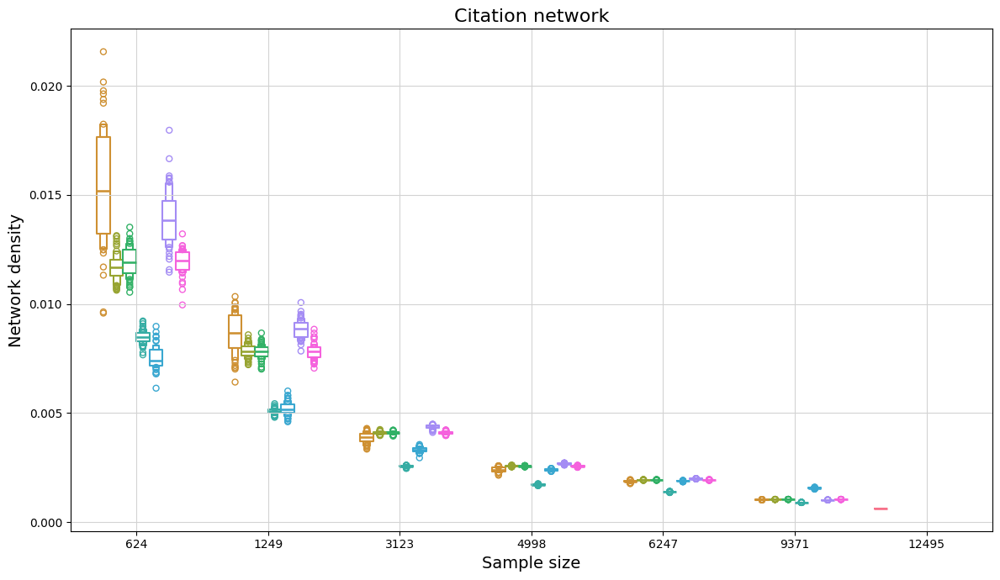

In [8]:
#No legends
df = pd.read_csv('data/real_net_sampling/combined_metrics_cit.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Citation network', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_cit.pdf', format='pdf')
plt.show()

## PCA

In [9]:
df = pd.read_csv('data/real_net_sampling/combined_metrics_cit.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 68.0%
PCA Component 2 EVR: 17.7%
PCA Component 3 EVR: 6.0%


In [11]:
df_pca.to_csv('data/pca/pca_cit.csv')

In [135]:
df_pca = pd.read_csv('data/pca/pca_cit.csv')

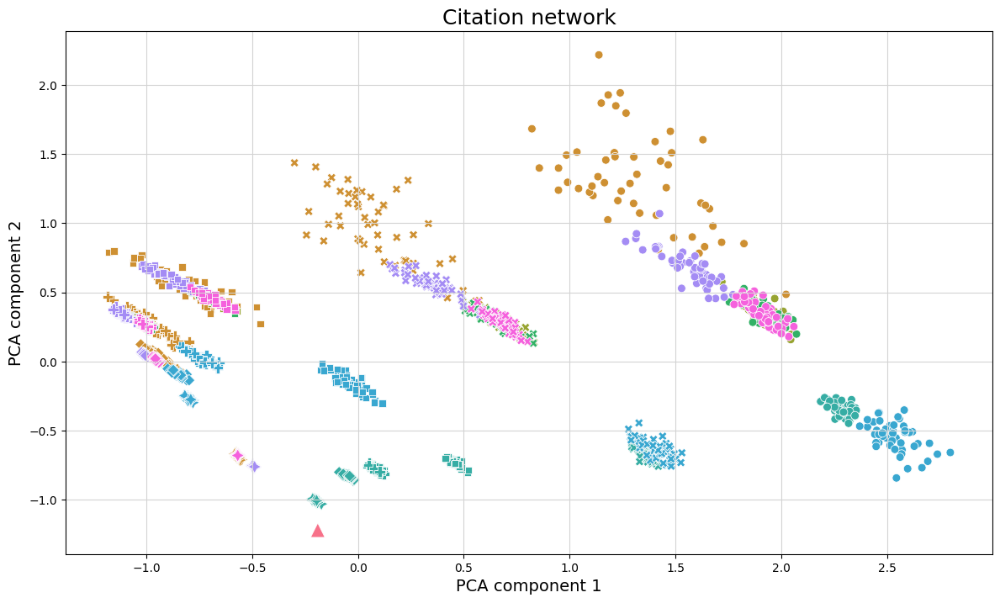

In [ ]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Citation network', fontsize=18)
plt.savefig('PCA_cit.pdf', format='pdf')
plt.show()

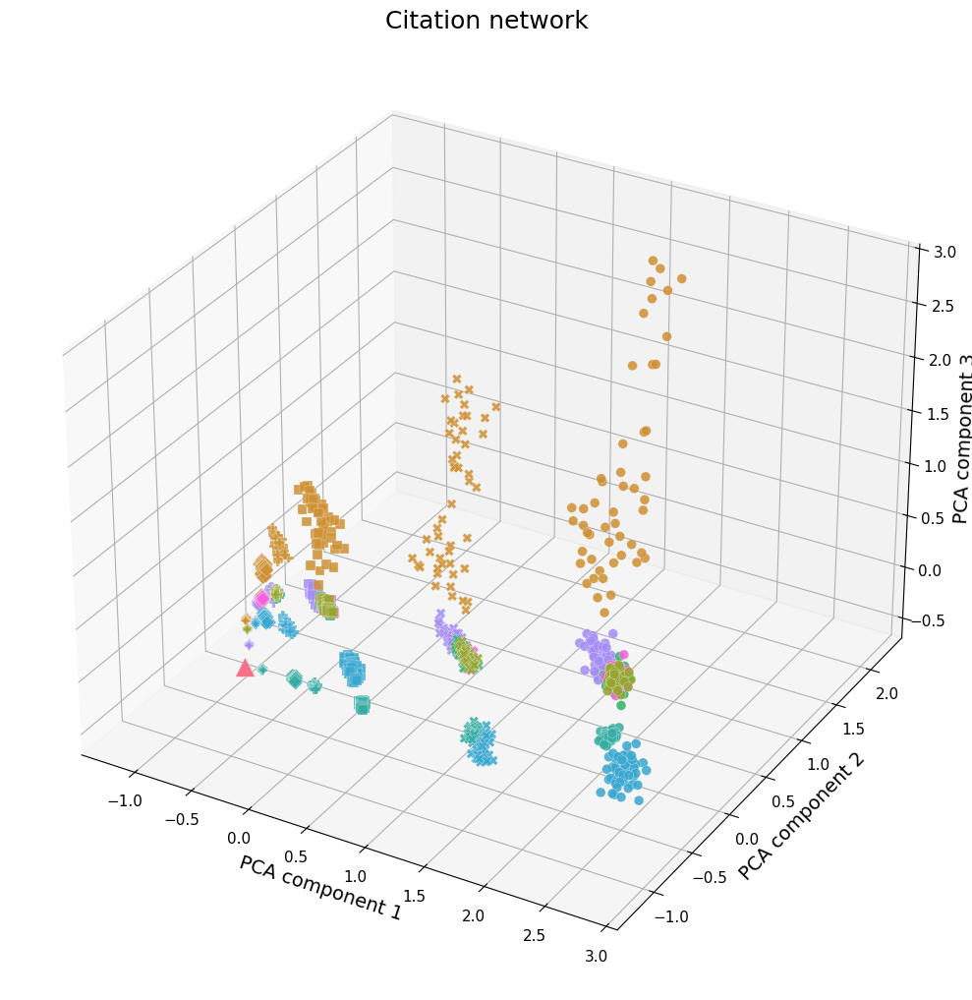

In [136]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Citation network', fontsize=18)
plt.savefig('PCA_cit_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

## ML

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[3])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.

In [5]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [ ]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [38]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [39]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([  0.,   0.,   0.,   0.,   0., 350.,   0.,   0.,   0.,   0.]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 <BarContainer object of 10 artists>)

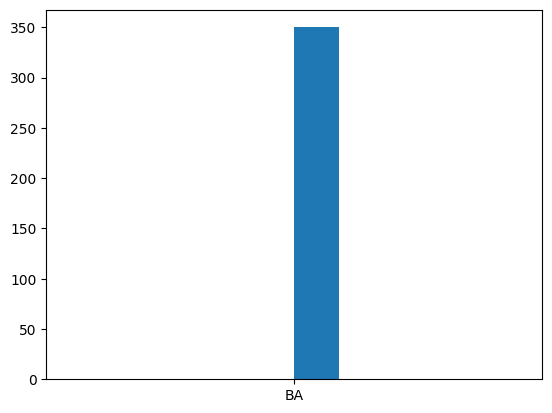

In [40]:
plt.hist(y_pred_cit)

In [49]:
display_column_names = {'assortativity': 'Assortativity', 'avg_spl': 'Mean SPL', 'betweenness_info_moment_1': 'Betweenness centrality (m=1)',
       'betweenness_info_moment_2': 'Betweenness centrality (m=2)', 'betweenness_info_moment_3': 'Betweenness centrality (m=3)',
       'betweenness_info_moment_4': 'Betweenness centrality (m=4)', 'betweenness_info_shannon': 'Betweenness centrality (entropy)',
       'closeness_info_moment_1': 'Closeness centrality (m=1)', 'closeness_info_moment_2': 'Closeness centrality (m=2)',
       'closeness_info_moment_3': 'Closeness centrality (m=3)', 'closeness_info_moment_4': 'Closeness centrality (m=4)',
       'closeness_info_shannon': 'Closeness centrality (entropy)', 'clustering_info_moment_1': 'Clustering (m=1)',
       'clustering_info_moment_2': 'Clustering (m=2)', 'clustering_info_moment_3': 'Clustering (m=3)',
       'clustering_info_moment_4': 'Clustering (m=4)', 'clustering_info_shannon': 'Clustering (entropy)',
       'complexity_coefficient': 'Complexity coefficient', 'degree_info_moment_1': 'Degree (m=1)',
       'degree_info_moment_2': 'Degree (m=2)', 'degree_info_moment_3': 'Degree (m=3)', 'degree_info_moment_4': 'Degree (m=4)',
       'degree_info_shannon': 'Degree (entropy)', 'eigenvector_info_moment_1': 'Eigenvector centrality (m=1)',
       'eigenvector_info_moment_2': 'Eigenvector centrality (m=2)', 'eigenvector_info_moment_3': 'Eigenvector centrality (m=3)',
       'eigenvector_info_moment_4': 'Eigenvector centrality (m=4)', 'eigenvector_info_shannon': 'Eigenvector centrality (entropy)',
       'global_efficiency': 'Global efficiency', 'kcore_info_moment_1': 'K-core (m=1)', 'kcore_info_moment_2':'K-core (m=2)',
       'kcore_info_moment_3':'K-core (m=3)', 'kcore_info_moment_4':'K-core (m=4)', 'kcore_info_shannon':'K-core (entropy)',
       'local_efficiency': 'Local efficiency', 'pagerank_info_moment_1': 'PageRank (m=1)', 'pagerank_info_moment_2':'PageRank (m=2)',
       'pagerank_info_moment_3':'PageRank (m=3)', 'pagerank_info_moment_4':'PageRank (m=4)',
       'pagerank_info_shannon':'PageRank (entropy)', 'spectral_distance_info_max': 'Max. Spectral distance',
       'spectral_distance_info_mean': 'Mean spectral distance', 'spectral_distance_info_moment_1': 'Spectral distance (m=1)',
       'spectral_distance_info_moment_2': 'Spectral distance (m=2)', 'spectral_distance_info_moment_3': 'Spectral distance (m=3)',
       'spectral_distance_info_moment_4': 'Spectral distance (m=4)', 'spectral_distance_info_shannon': 'Spectral distance (entropy)',
       'transitivity': 'Transitivity'}

#wew

In [43]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

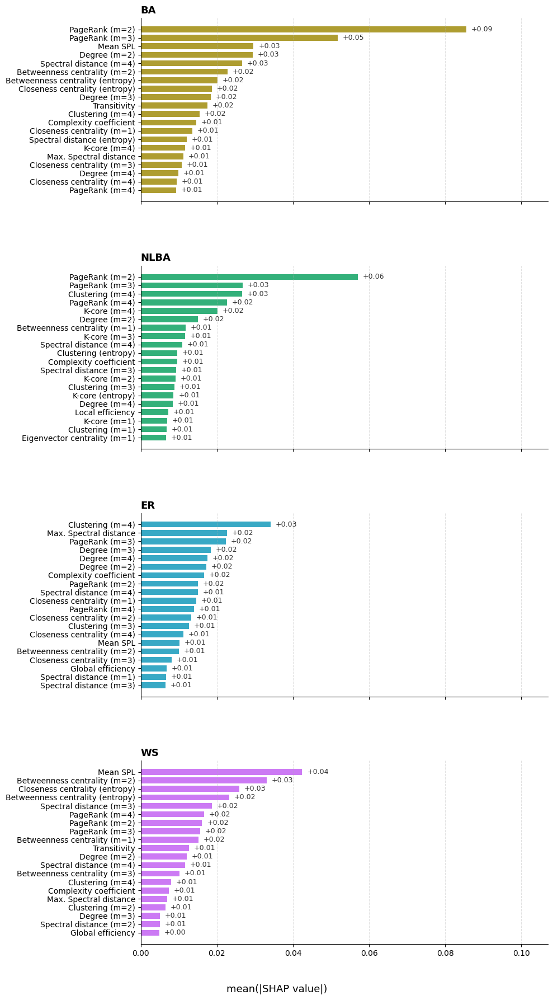

In [44]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_0.4N.pdf', format='pdf')
plt.show()

# Budapest network

## Sampling and metrics computation

In [8]:
buda = nx.read_edgelist("data/nets/budapest_connections.txt")
buda.remove_edges_from(nx.selfloop_edges(buda))
maior_componente = max(nx.connected_components(buda), key=len)
buda = buda.subgraph(maior_componente).copy()

graph_list = [buda]
buda_len = len(graph_list[0])
print(buda_len)

467


In [9]:
len(graph_list[0].edges())

980

Here we need the following sizes: 5%, 10%, 25%, 40%, 50% and 75%, so:


In [91]:
sizes_buda = [int(buda_len*0.05),int(buda_len*0.1),int(buda_len*0.25),
            int(buda_len*0.4),int(buda_len*0.5),int(buda_len*0.75)]

och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=sizes_buda, runs=50)

Sampling graphs: 100%|██████████| 2100/2100 [00:00<00:00, 7948.26it/s]


In [92]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [93]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/real_net_sampling/swp/')

Metric 14/14 (transitivity): 100%|██████████| 2101/2101 [00:01<00:00, 2068.32it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,467,980,0.009006,-0.200460,4.924125,0.008439,0.001118,0.000281,...,1.085093e-08,0.000000,13.453624,2.648936,2.648936,8.394004,34.373529,190.522970,4.007489,0.120394
1,0,snowball,23,59,0.233202,-0.545392,1.830040,0.039526,0.013312,0.005108,...,4.265582e-05,0.426229,6.164414,2.987449,2.987449,10.260870,38.614615,157.315690,4.255564,0.361224
2,0,snowball,23,32,0.126482,-0.421225,2.758893,0.083757,0.030660,0.014317,...,3.522467e-05,0.258019,4.242641,2.215620,2.215620,5.565217,15.117903,44.136106,3.520157,0.230769
3,0,snowball,23,42,0.166008,-0.488390,1.833992,0.039714,0.031037,0.026155,...,1.799935e-04,0.258019,5.567764,2.483090,2.483090,7.304348,24.725594,95.742911,3.703658,0.234375
4,0,snowball,23,39,0.154150,-0.230035,3.000000,0.095238,0.027403,0.009777,...,1.095399e-05,0.000000,4.000000,2.482815,2.482815,6.782609,19.381855,57.618147,3.576996,0.404255
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,0,frontier_sampling,350,828,0.013557,-0.217168,4.181957,0.009144,0.001410,0.000385,...,2.250387e-08,0.000000,12.922848,2.828228,2.828228,9.462857,39.867477,219.648784,4.182623,0.137672
2097,0,frontier_sampling,350,829,0.013573,-0.232708,3.968154,0.008529,0.001415,0.000412,...,2.961302e-08,0.000000,13.190906,2.819626,2.819626,9.474286,40.546668,228.975151,4.177527,0.130409
2098,0,frontier_sampling,350,824,0.013492,-0.213572,4.553271,0.010211,0.001530,0.000401,...,2.019572e-08,0.000000,12.727922,2.824873,2.824873,9.417143,39.421812,215.113665,4.171609,0.140495
2099,0,frontier_sampling,350,817,0.013377,-0.226041,4.182464,0.009145,0.001438,0.000396,...,2.692486e-08,0.000000,13.000000,2.802699,2.802699,9.337143,39.477406,219.604245,4.164647,0.135178


In [94]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/real_net_sampling/swp/', output_filename='combined_metrics_buda.csv'
)

Successfully combined 14 files into 'data/real_net_sampling/swp/combined_metrics_buda.csv' (2101 rows, 53 columns).


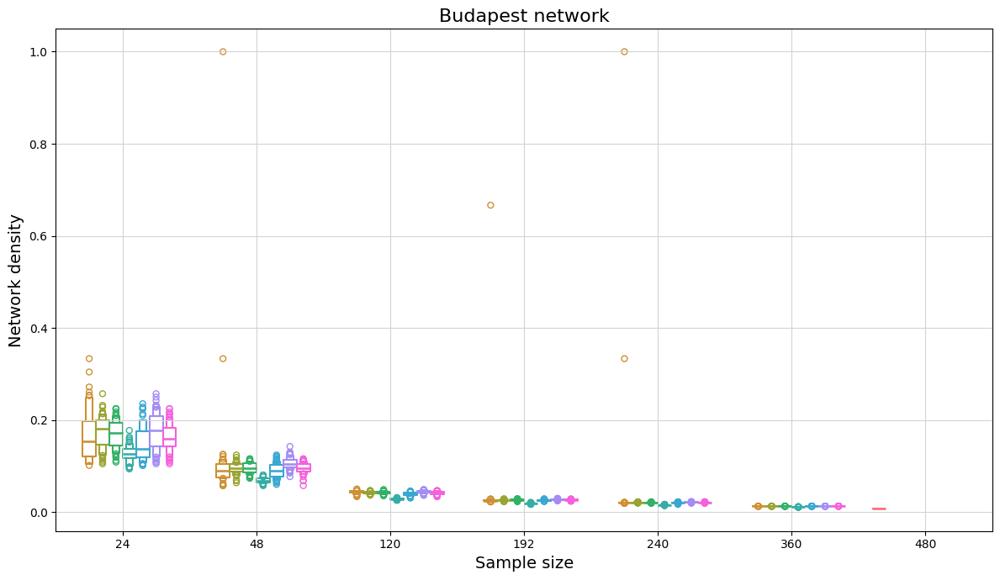

In [95]:
#No legends
df_test = pd.read_csv('data/real_net_sampling/combined_metrics_buda.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Budapest network', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_buda.pdf', format='pdf')
plt.show()

## PCA

In [128]:
df = pd.read_csv('data/real_net_sampling/combined_metrics_buda.csv')#.dropna()

In [97]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 62.0%
PCA Component 2 EVR: 21.9%
PCA Component 3 EVR: 6.6%


In [98]:
df_pca.to_csv('data/pca/pca_buda.csv')

In [129]:
df_pca = pd.read_csv('data/pca/pca_buda.csv', index_col=0)

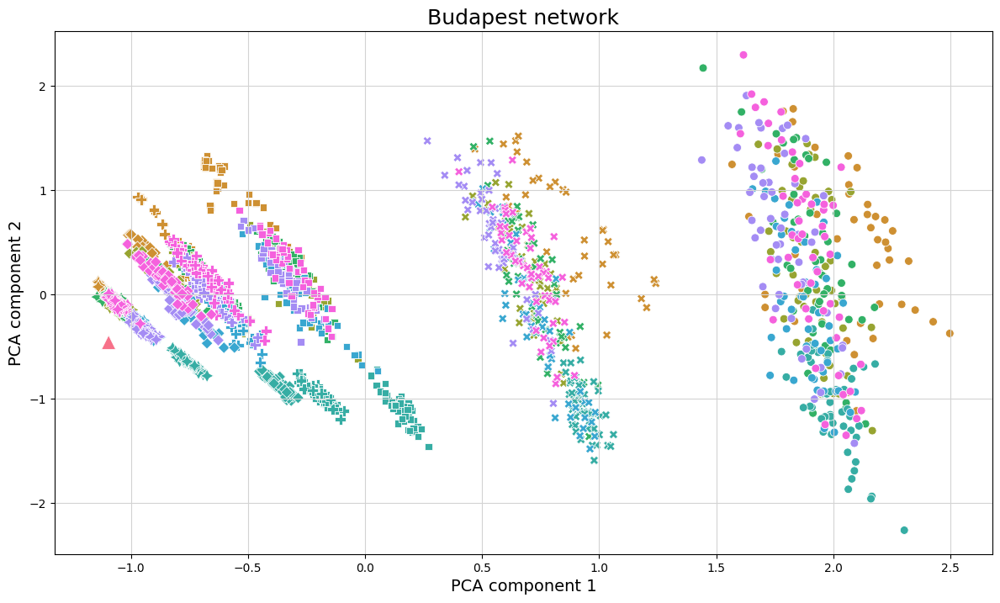

In [100]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Budapest network', fontsize=18)
plt.savefig('PCA_buda.pdf', format='pdf')
plt.show()

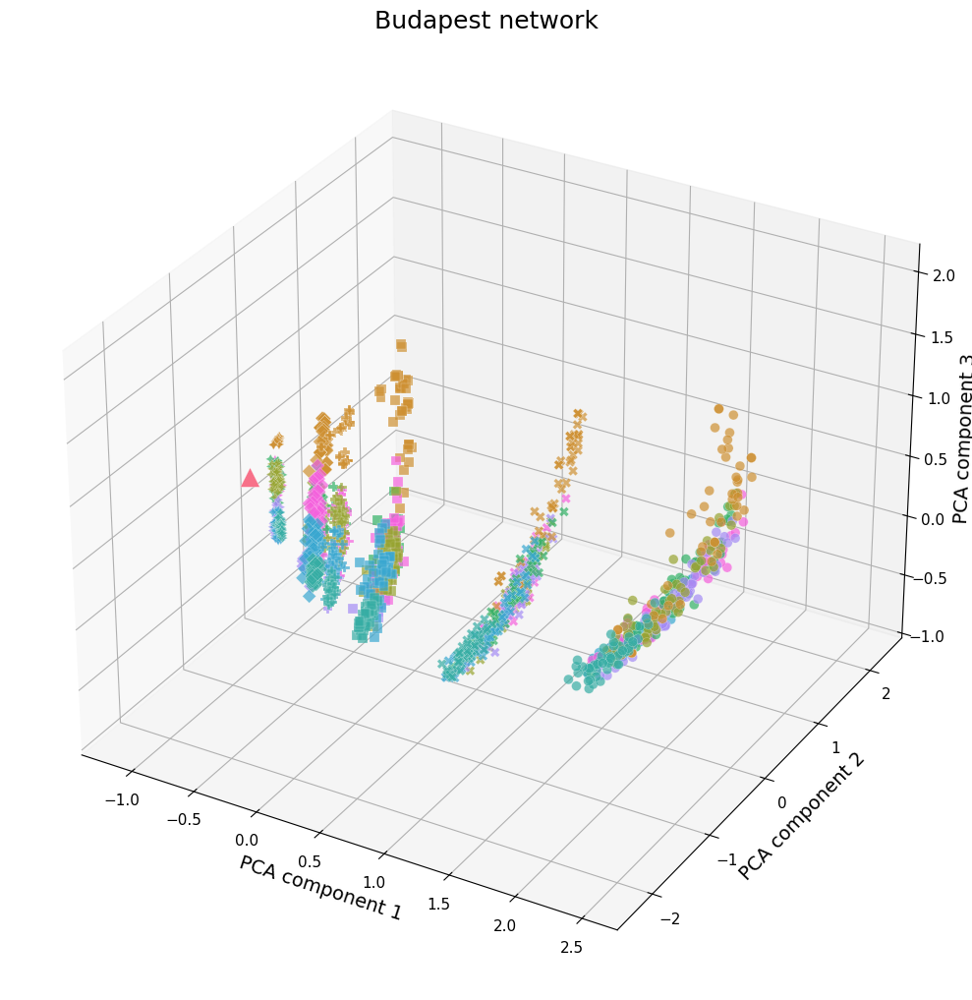

In [130]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.7,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Budapest network', fontsize=18)
plt.savefig('PCA_buda_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

## ML

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[3])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'max_depth': [2, 5, 7, 9]
}

In [ ]:
grid_clf = GridSearchCV(RandomForestClassifier(n_jobs=-1), param_grid, cv=10)
grid_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ier(n_jobs=-1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >

In [46]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [47]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([156.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 194.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

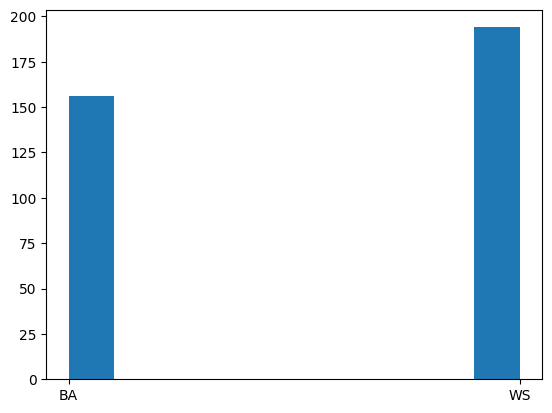

In [48]:
plt.hist(y_pred_buda)

In [50]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

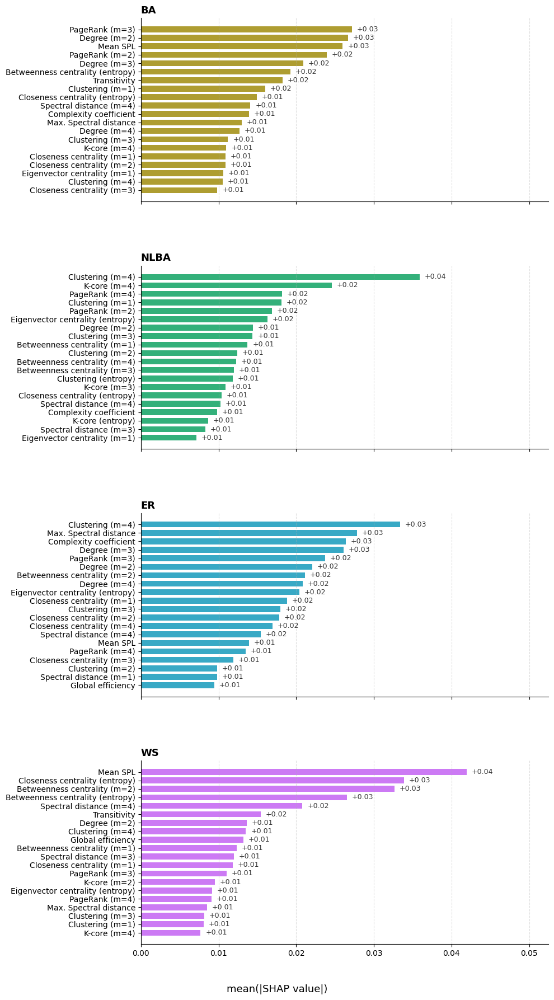

In [51]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_budapest_0.4N.pdf', format='pdf')
plt.show()

# Displaying classification results

In [52]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,BA,BA,BA,BA
1,BA,WS,BA,WS
2,BA,BA,BA,WS
3,BA,WS,BA,BA
4,BA,BA,BA,BA
...,...,...,...,...
345,WS,WS,BA,WS
346,WS,BA,BA,WS
347,BA,WS,BA,WS
348,WS,WS,BA,BA


In [53]:
res_preds.to_csv('results/y_test_predicts_real_nets.csv')

/tmp/ipykernel_70299/1797203623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_70299/1797203623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_70299/1797203623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_70299/1797203623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


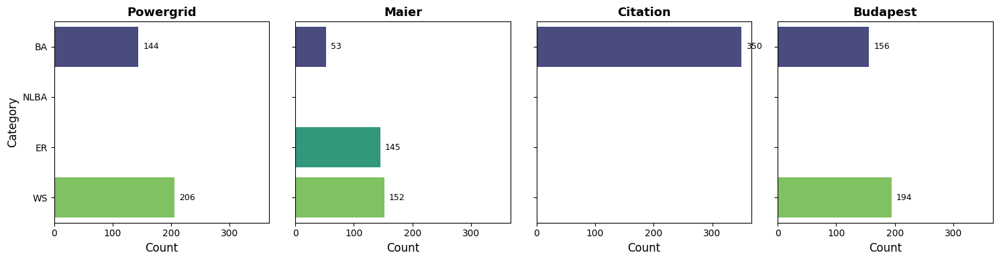

In [54]:
df = pd.read_csv('results/y_test_predicts_real_nets.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('categories_distribution_0.4N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()

# Dispersion distances

In [10]:
#=== Synth networks ===
#BA
df_pca = pd.read_csv('data/pca/pca_ba.csv', index_col=0)
swp1 = calculate_dispersion_distance(df_pca)

#NLBA
df_pca = pd.read_csv('data/pca/pca_nlba.csv', index_col=0)
swp2 = calculate_dispersion_distance(df_pca)

#ER
df_pca = pd.read_csv('data/pca/pca_er.csv', index_col=0)
swp3 = calculate_dispersion_distance(df_pca)

#WS
df_pca = pd.read_csv('data/pca/pca_ws.csv', index_col=0)
swp4 = calculate_dispersion_distance(df_pca)
#Group and concatenate all the data above 

#=== Real networks ====
#PG
df_pca = pd.read_csv('data/pca/pca_pg.csv', index_col=0)
swp5 = calculate_dispersion_distance(df_pca)

#maier
df_pca = pd.read_csv('data/pca/pca_maier.csv', index_col=0)
swp6 = calculate_dispersion_distance(df_pca)

#citation
df_pca = pd.read_csv('data/pca/pca_cit.csv', index_col=0)
swp7 = calculate_dispersion_distance(df_pca)

#Budapest
df_pca = pd.read_csv('data/pca/pca_buda.csv', index_col=0)
swp8 = calculate_dispersion_distance(df_pca)

#--- Concats everything ---
res = pd.concat([
    #BA - this is the only one that keeps the 'method' and 'sample_size' columns
    swp1.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_BA', 'var': 'var_BA'}),
    #NLBA                                                                                
    swp2.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_NLBA', 'var': 'var_NLBA'}),
    #ER                                                                                  
    swp3.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_ER', 'var': 'var_ER'}),
    #WS     
    swp4.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_WS', 'var': 'var_WS'}),  
    #PG     
    swp5.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_PG', 'var': 'var_PG'}),   
    #maier     
    swp6.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_Maier', 'var': 'var_Maier'}), 
    #Citation     
    swp7.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_Cit', 'var': 'var_Cit'}),
    #maier     
    swp8.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_Budapest', 'var': 'var_Budapest'}),                                                                                                                                                                                                                                                          
], axis=1)
res.to_csv('PCA_distances_all.csv')
res

,method,sample_size,mean_BA,var_BA,mean_NLBA,var_NLBA,mean_ER,var_ER,mean_WS,var_WS,mean_PG,var_PG,mean_Maier,var_Maier,mean_Cit,var_Cit,mean_Budapest,var_Budapest
0,IRWS,50,3.926473,0.003882,3.842673,0.002964,4.089552,0.016506,3.506119,0.014366,2.829277,0.109986,3.225245,0.012295,2.637564,0.001340,3.302200,0.055013
6,MHRW,50,4.541569,0.020453,4.628595,0.010941,4.745190,0.039076,3.700652,0.041825,2.733534,0.013129,3.872962,0.045793,2.975761,0.007317,3.195527,0.031087
12,RWS,50,4.435474,0.022340,4.369476,0.003423,4.731076,0.039583,3.721879,0.038816,2.889042,0.101887,3.909766,0.036556,2.627570,0.001308,3.265266,0.041982
18,forest_fire_sampling,50,3.902851,0.003691,3.779295,0.002535,3.876736,0.008493,3.441057,0.021743,2.852265,0.095455,3.212688,0.009168,2.605768,0.003614,3.262186,0.065554
24,frontier_sampling,50,3.923854,0.004648,3.838448,0.002927,4.095324,0.015999,3.490905,0.015209,2.820198,0.103818,3.196340,0.011950,2.625653,0.001072,3.371359,0.081873
30,snowball,50,4.371237,0.002937,4.600945,0.003076,3.931209,0.003589,3.506896,0.042259,2.960345,0.142405,4.029282,0.062470,3.112375,0.105335,3.425087,0.057854
36,traceroute,50,4.242401,0.004092,4.530698,0.005549,4.416801,0.009010,5.065196,0.001320,3.325579,0.005259,4.050945,0.008703,2.743703,0.001199,3.536626,0.121688
13,RWS,100,3.677154,0.005148,3.650152,0.002204,4.315669,0.021292,2.106909,0.052842,1.649885,0.046356,3.096827,0.091550,1.742084,0.000525,2.023265,0.015057
19,forest_fire_sampling,100,2.745856,0.009962,2.183518,0.001528,3.342882,0.006596,1.794455,0.016719,1.598642,0.036059,1.848532,0.019685,1.863770,0.002974,2.067017,0.039973
1,IRWS,100,2.785729,0.011769,2.292907,0.001792,3.498690,0.008396,1.810941,0.012410,1.717711,0.125690,1.841332,0.024236,1.741566,0.000549,2.098314,0.045620


# Complementary results: all other B

In [157]:
size_sample = 0.75
size_sample_index = 5

## B=5%

### Powergrid

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [10]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [11]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([262.,   0.,   0.,   0.,   0.,  63.,   0.,   0.,   0.,  25.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

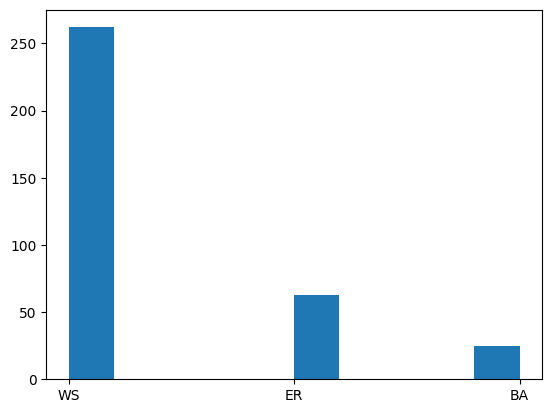

In [12]:
plt.hist(y_pred_pg)

In [13]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

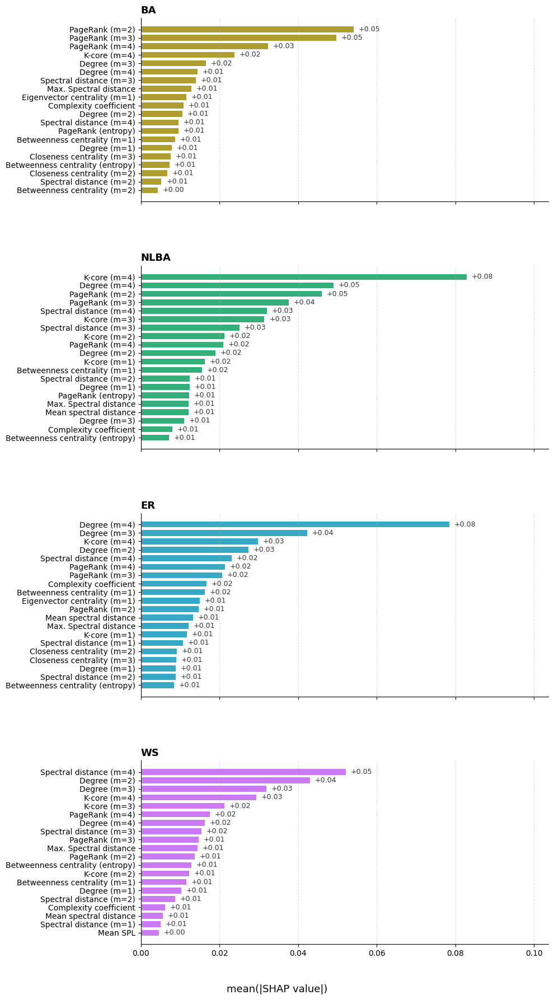

In [14]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Maier

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [18]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [19]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 21.,   0.,   0., 196.,   0.,   0.,  89.,   0.,   0.,  44.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

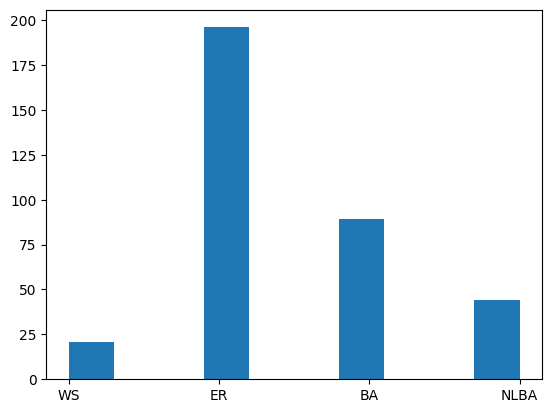

In [20]:
plt.hist(y_pred_maier)

In [21]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

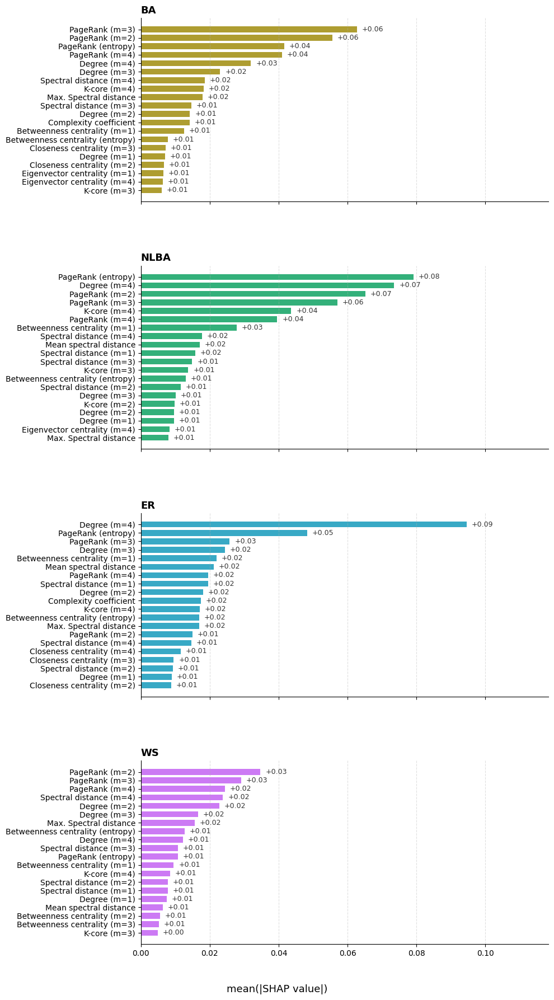

In [22]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Citation

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [32]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [37]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 35.,   0.,   0.,   0.,   0., 314.,   0.,   0.,   0.,   1.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

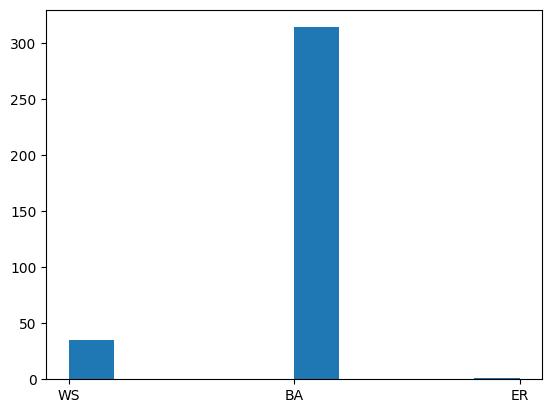

In [38]:
plt.hist(y_pred_cit)

In [39]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

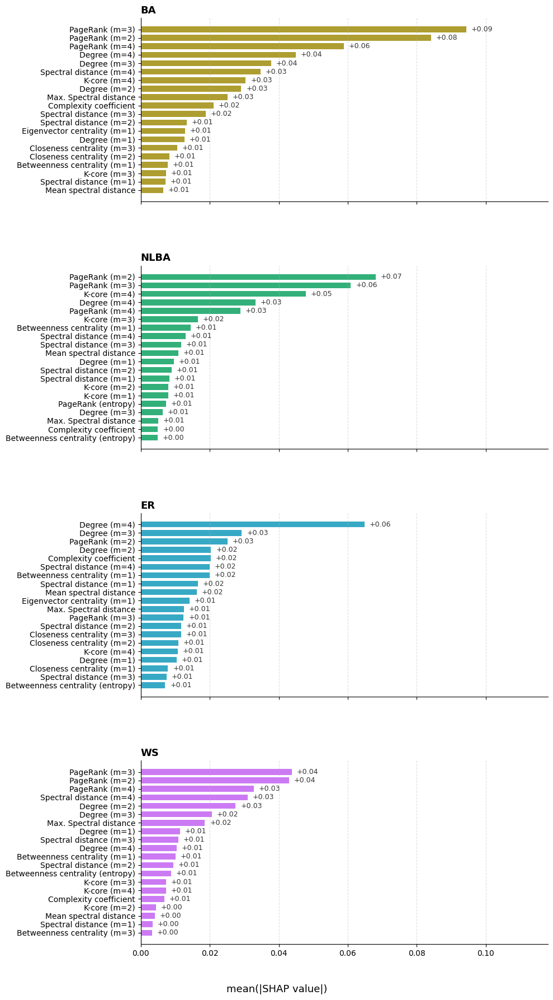

In [40]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Budapest

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [44]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [45]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 76.,   0.,   0., 240.,   0.,   0.,   2.,   0.,   0.,  32.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

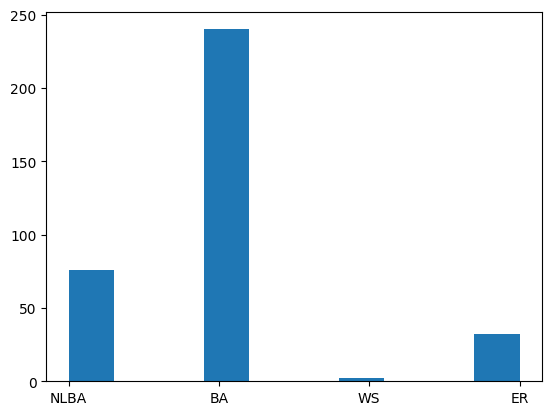

In [46]:
plt.hist(y_pred_buda)

In [47]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

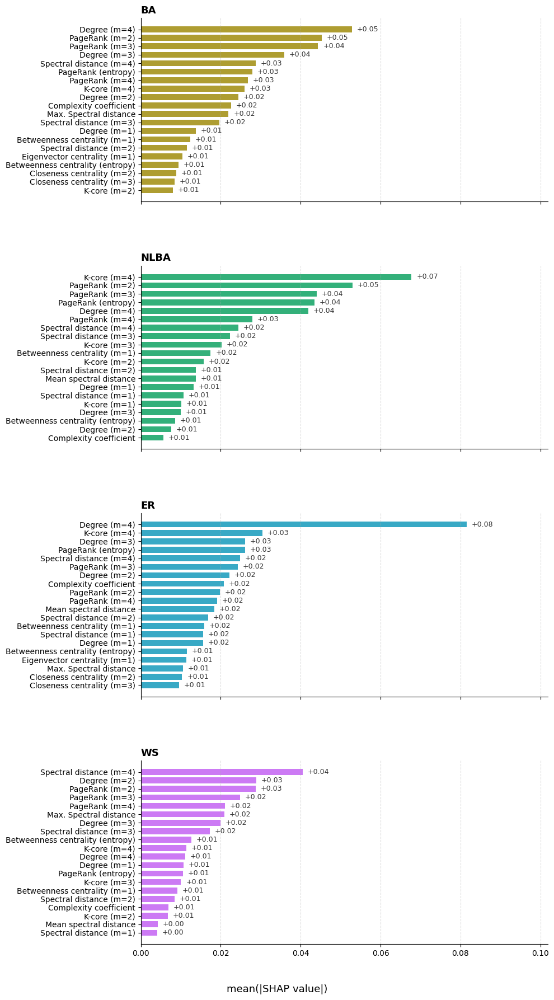

In [48]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_buda_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Displaying classification results

In [49]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,WS,WS,WS,NLBA
1,WS,ER,WS,BA
2,WS,WS,WS,BA
3,WS,WS,BA,BA
4,WS,WS,BA,BA
...,...,...,...,...
345,BA,BA,BA,BA
346,WS,BA,BA,BA
347,WS,BA,BA,NLBA
348,WS,ER,BA,BA


In [50]:
res_preds.to_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


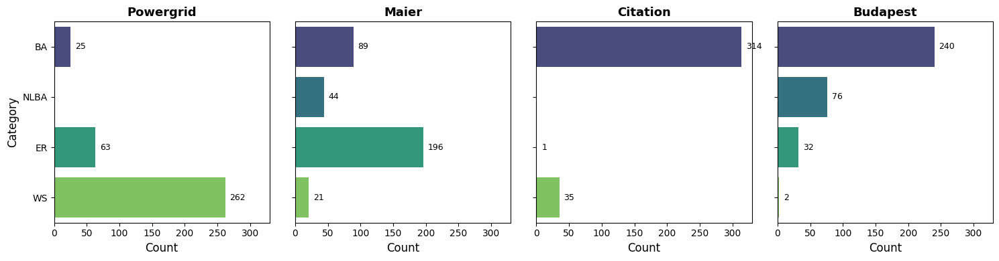

In [51]:
df = pd.read_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('results/complementary/categories_distribution_' + str(size_sample) + 'N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()

## B=10%

### Powergrid

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [56]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [57]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([152.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 198.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

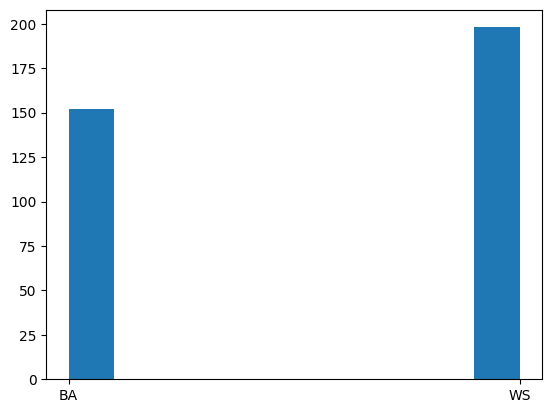

In [58]:
plt.hist(y_pred_pg)

In [59]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

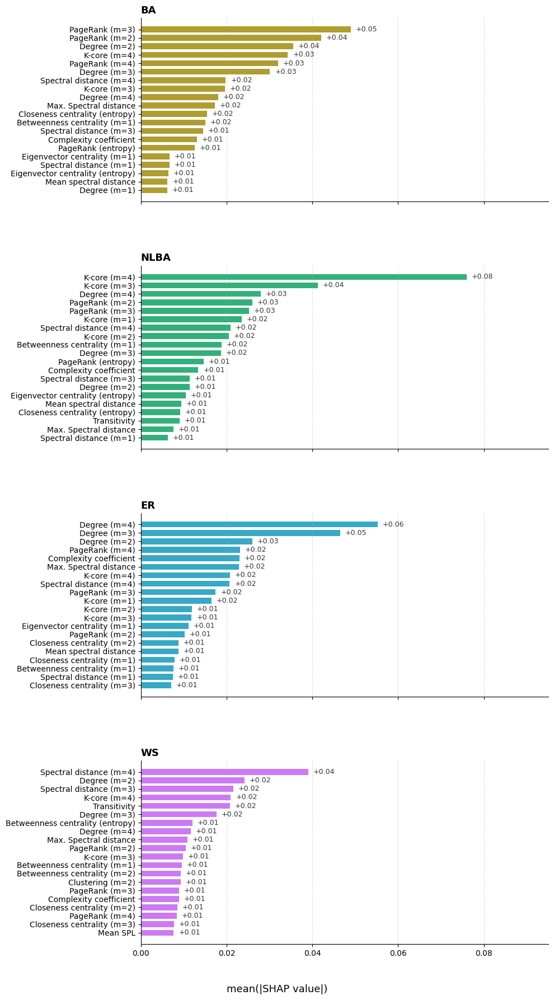

In [60]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Maier

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [64]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [65]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([147.,   0.,   0.,  45.,   0.,   0., 143.,   0.,   0.,  15.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

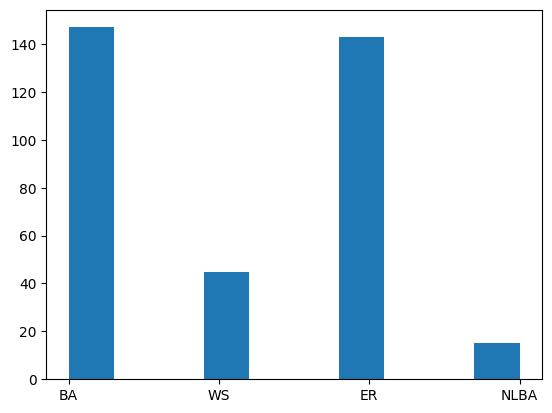

In [66]:
plt.hist(y_pred_maier)

In [67]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

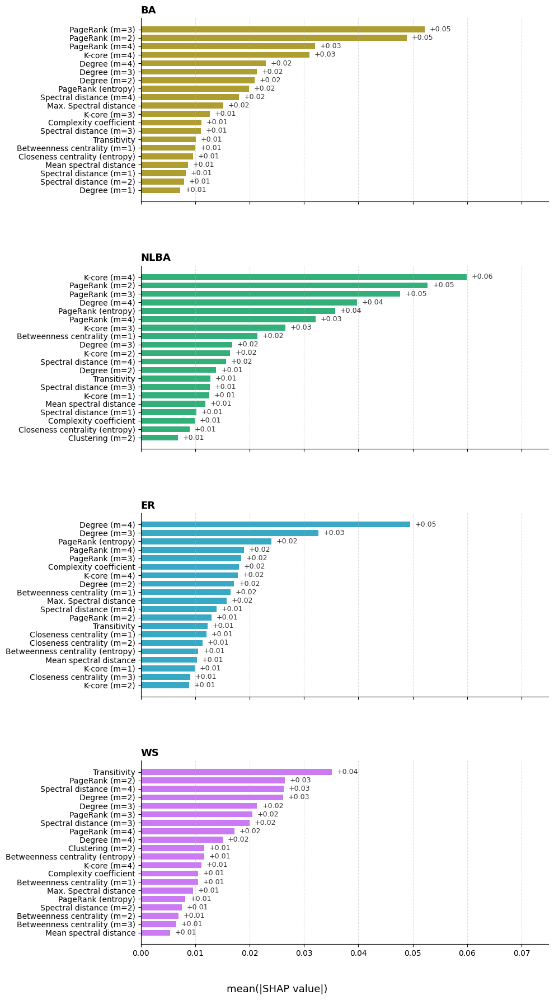

In [68]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Citation

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [71]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [72]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 42.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 308.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

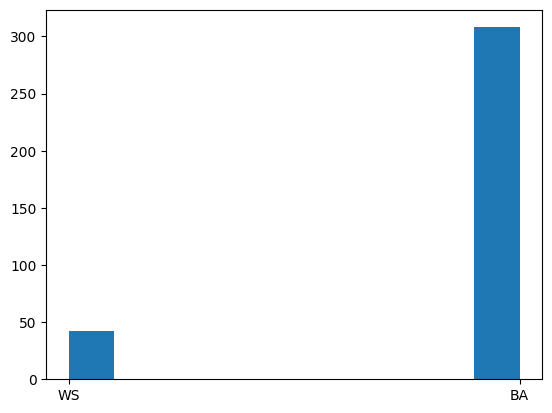

In [73]:
plt.hist(y_pred_cit)

In [74]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

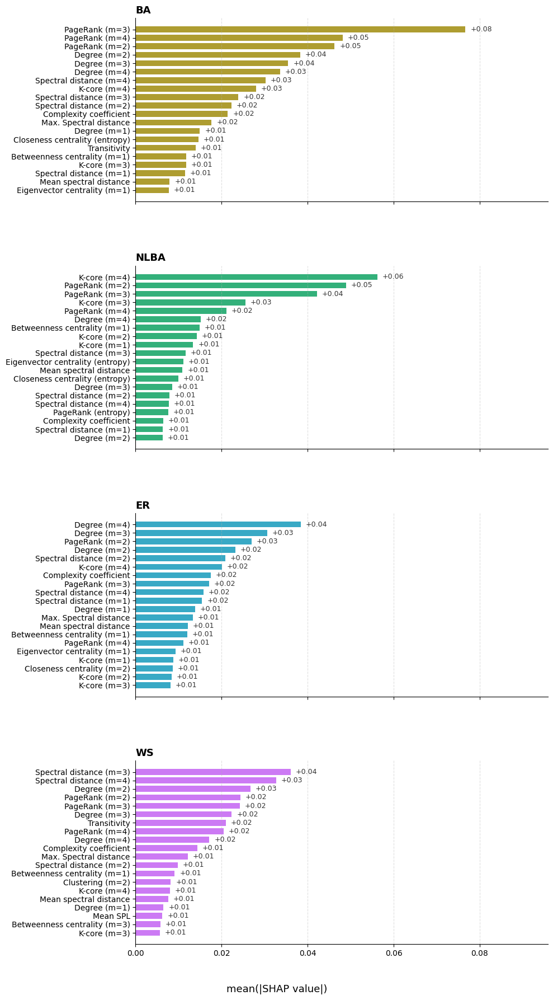

In [75]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Budapest

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [79]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [80]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 57.,   0.,   0., 252.,   0.,   0.,  12.,   0.,   0.,  29.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

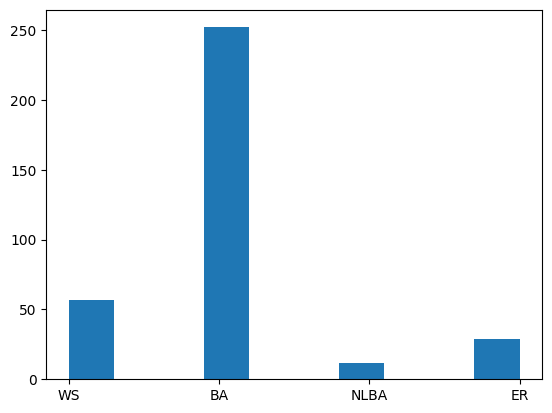

In [81]:
plt.hist(y_pred_buda)

In [82]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

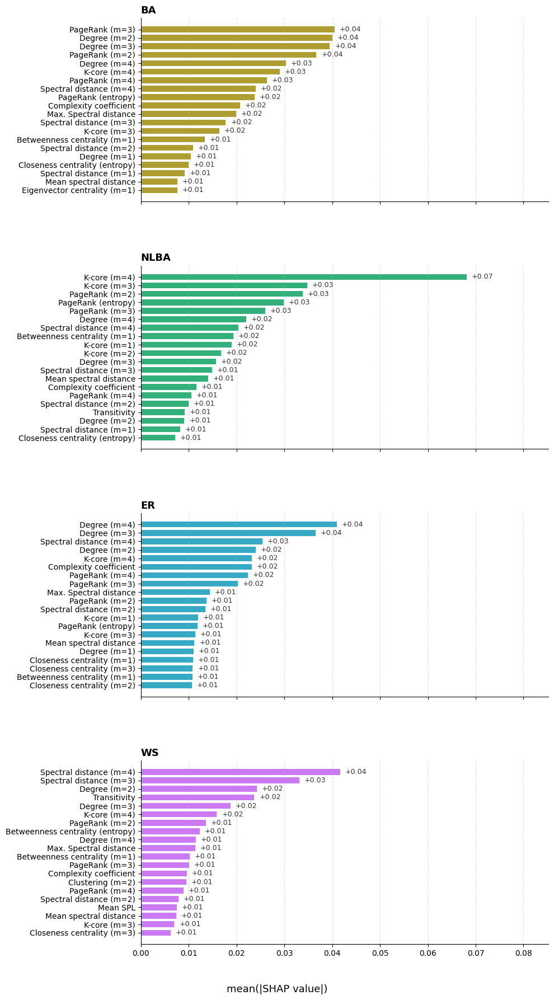

In [83]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_buda_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Displaying classification results

In [84]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,BA,BA,WS,WS
1,BA,BA,WS,WS
2,BA,BA,WS,WS
3,BA,BA,WS,BA
4,BA,BA,WS,BA
...,...,...,...,...
345,WS,BA,BA,WS
346,WS,WS,BA,BA
347,BA,ER,BA,BA
348,WS,BA,BA,BA


In [85]:
res_preds.to_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


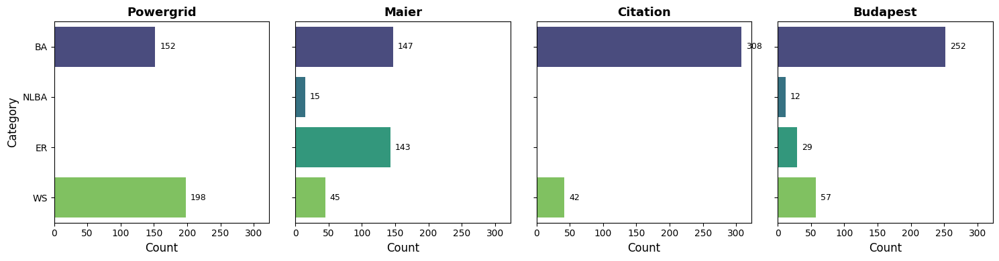

In [86]:
df = pd.read_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('results/complementary/categories_distribution_' + str(size_sample) + 'N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()

## B=25%

### Powergrid

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [91]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [92]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([119.,   0.,   0.,   0.,   0., 215.,   0.,   0.,   0.,  16.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

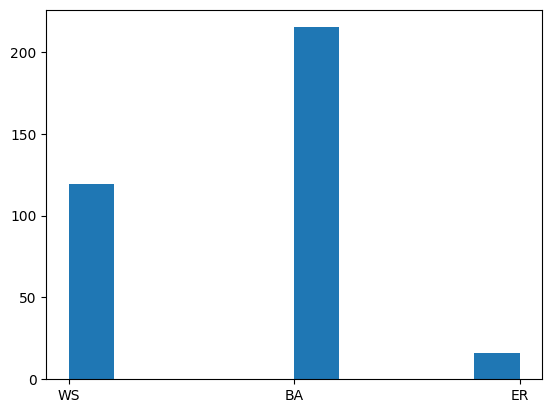

In [93]:
plt.hist(y_pred_pg)

In [94]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

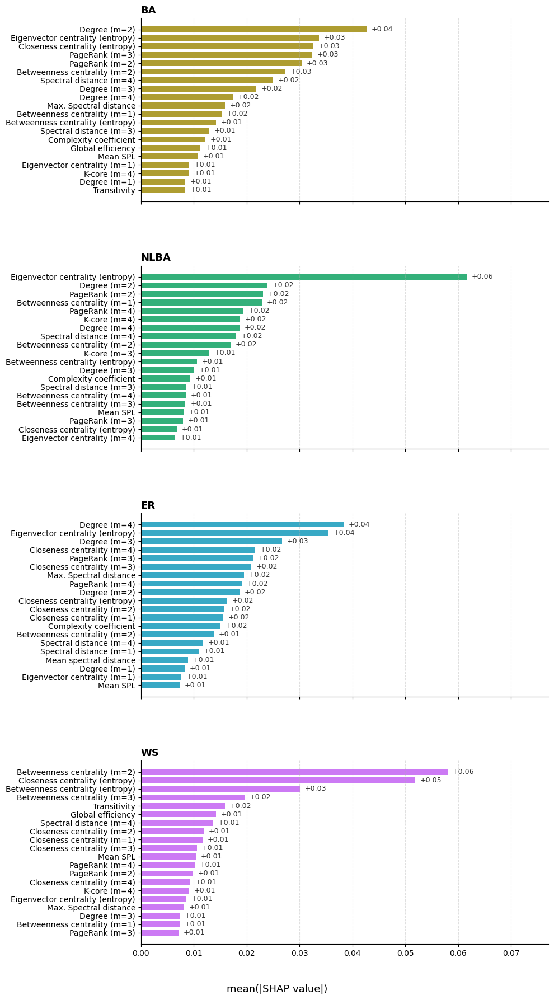

In [95]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Maier

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [99]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [100]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([176.,   0.,   0.,   0.,   0., 140.,   0.,   0.,   0.,  34.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

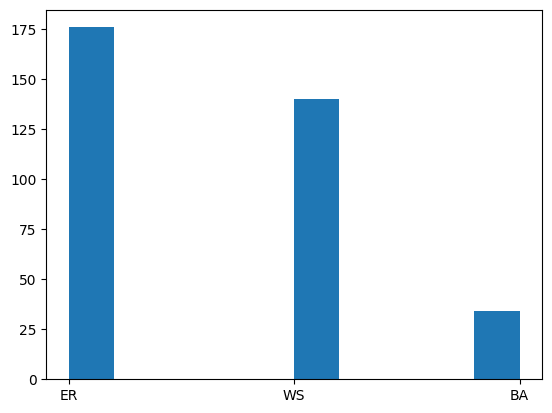

In [101]:
plt.hist(y_pred_maier)

In [102]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

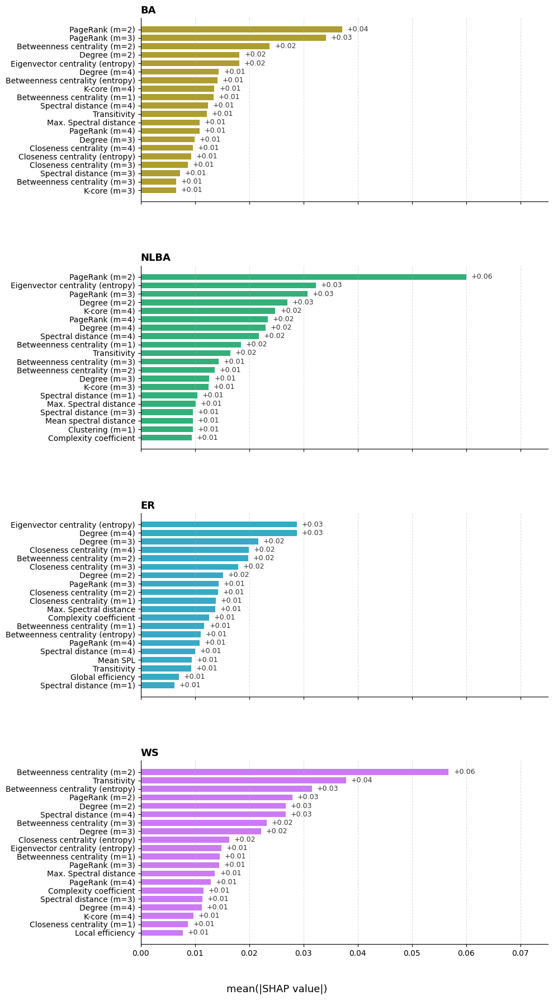

In [103]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Citation

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [106]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [107]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([313.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,  37.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

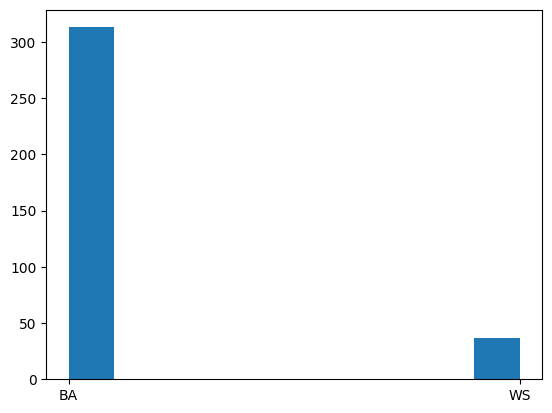

In [108]:
plt.hist(y_pred_cit)

In [109]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

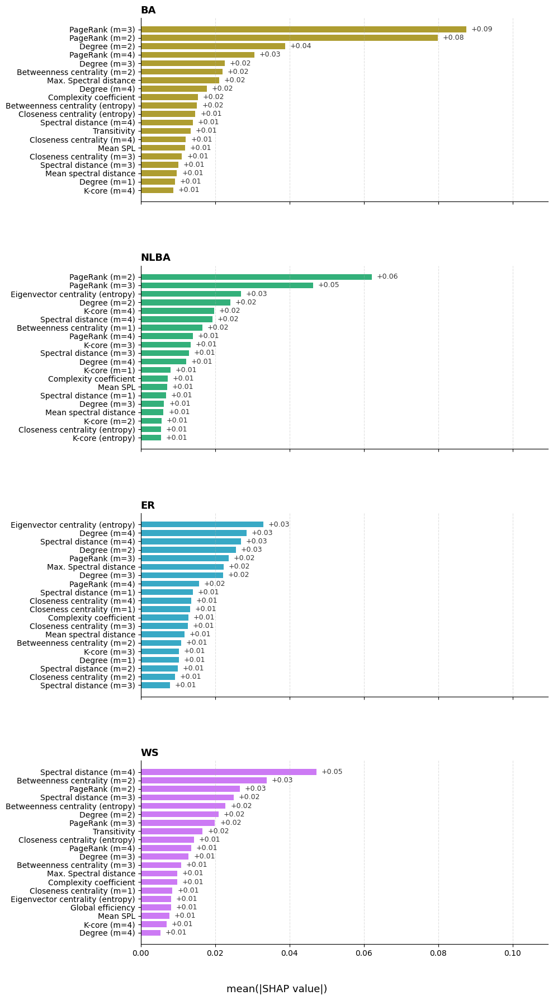

In [110]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Budapest

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [114]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [115]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([202.,   0.,   0.,   0.,   0., 105.,   0.,   0.,   0.,  43.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

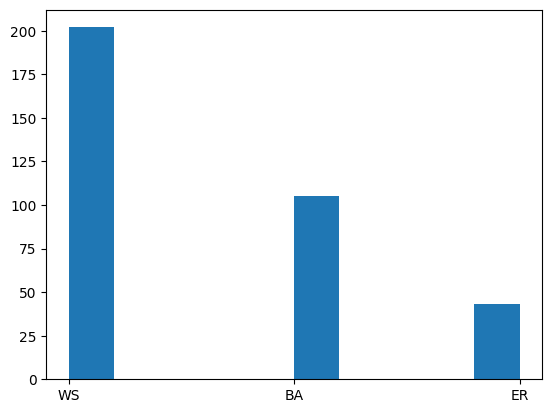

In [116]:
plt.hist(y_pred_buda)

In [117]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

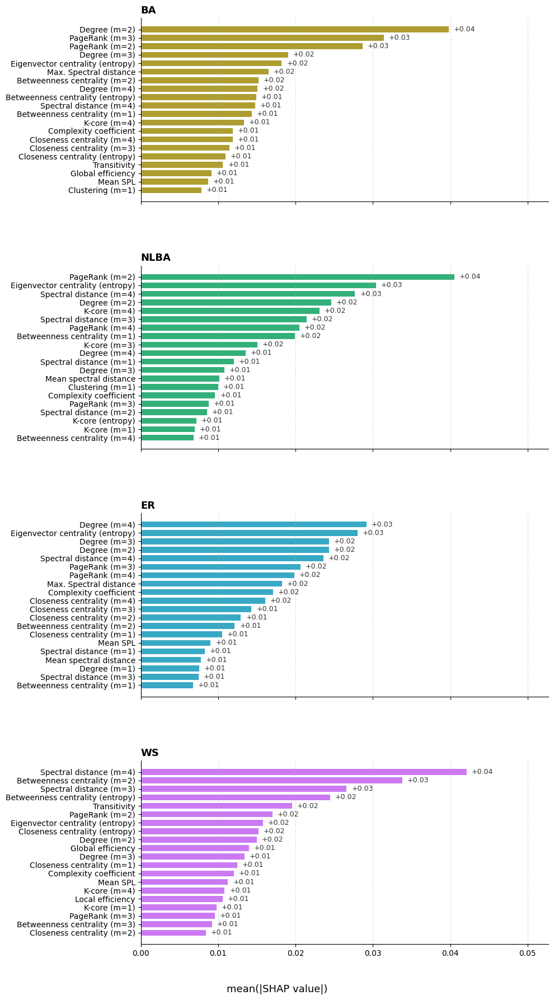

In [118]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_buda_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Displaying classification results

In [119]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,WS,ER,BA,WS
1,BA,WS,WS,WS
2,BA,ER,WS,WS
3,BA,BA,WS,WS
4,BA,BA,BA,WS
...,...,...,...,...
345,WS,WS,BA,WS
346,WS,WS,BA,WS
347,WS,ER,BA,BA
348,BA,WS,BA,BA


In [120]:
res_preds.to_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


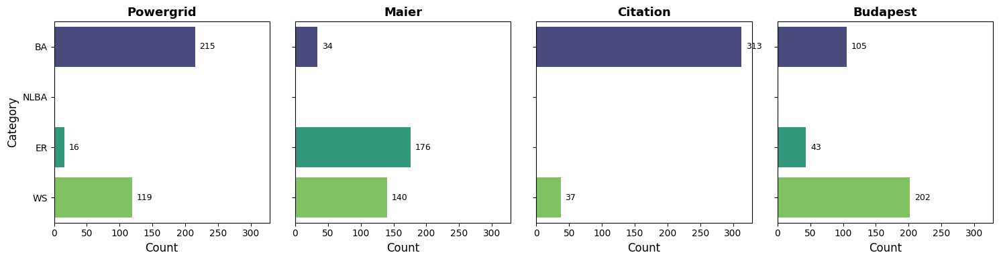

In [121]:
df = pd.read_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('results/complementary/categories_distribution_' + str(size_sample) + 'N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()

## B=50%

### Powergrid

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [126]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [127]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([177.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 173.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

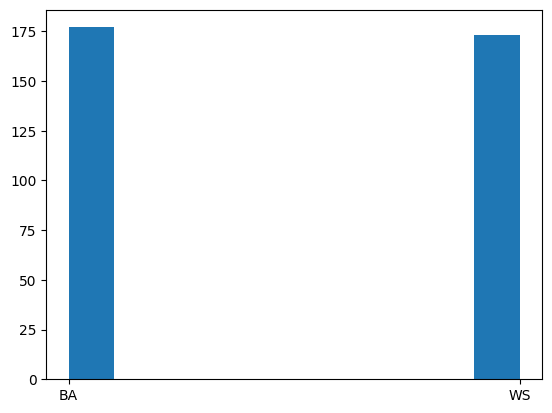

In [128]:
plt.hist(y_pred_pg)

In [129]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

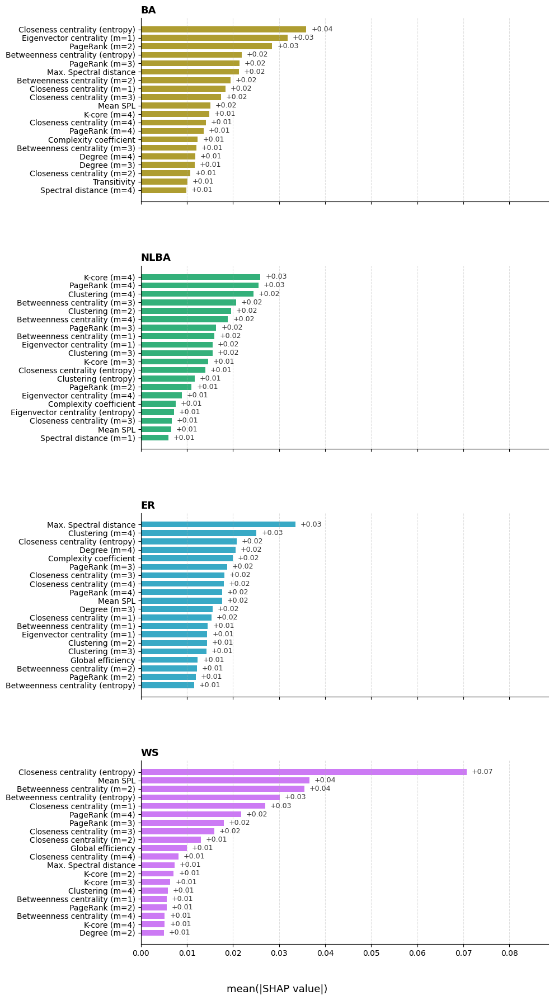

In [130]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Maier

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [134]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [135]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([164.,   0.,   0.,   0.,   0.,  52.,   0.,   0.,   0., 134.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

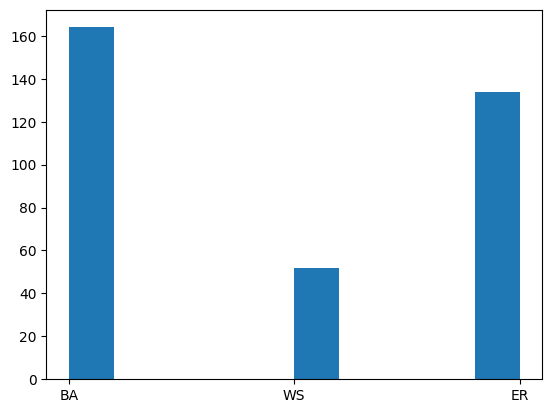

In [136]:
plt.hist(y_pred_maier)

In [137]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

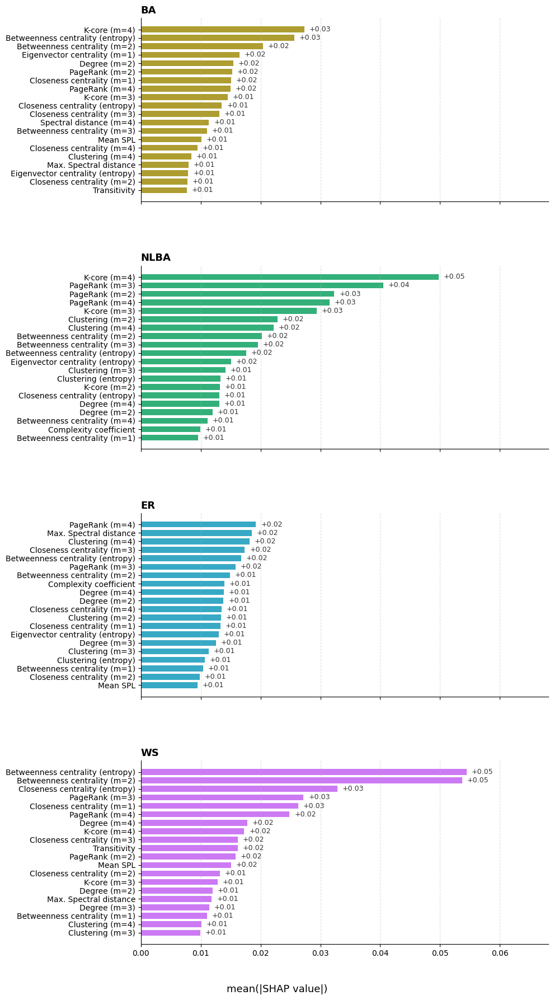

In [138]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Citation

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [141]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [142]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([  0.,   0.,   0.,   0.,   0., 350.,   0.,   0.,   0.,   0.]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 <BarContainer object of 10 artists>)

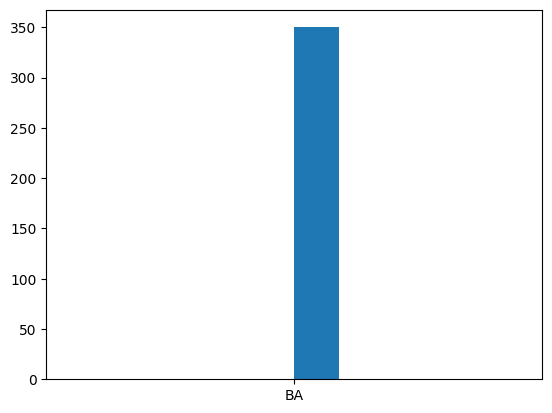

In [143]:
plt.hist(y_pred_cit)

In [144]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

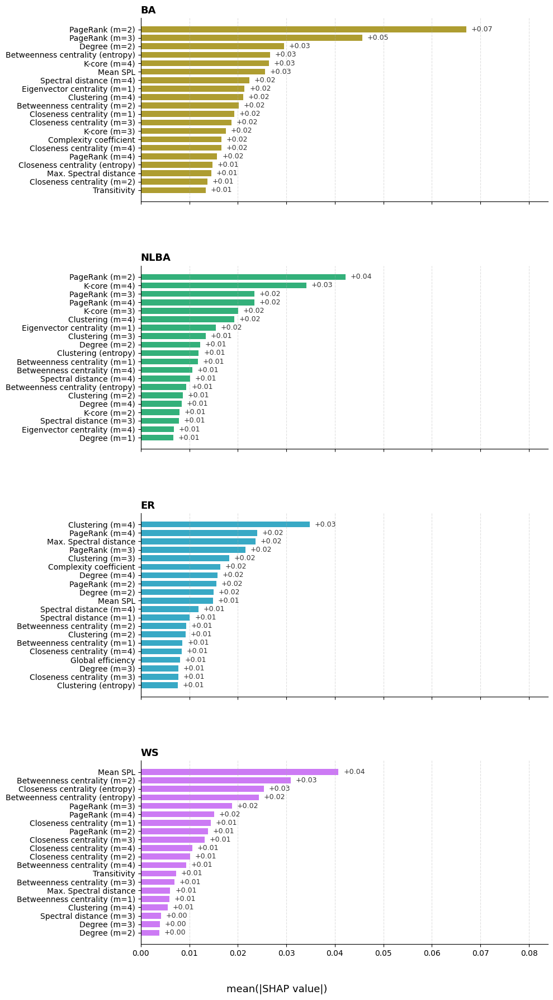

In [145]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Budapest

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [149]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [150]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([323.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,  27.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

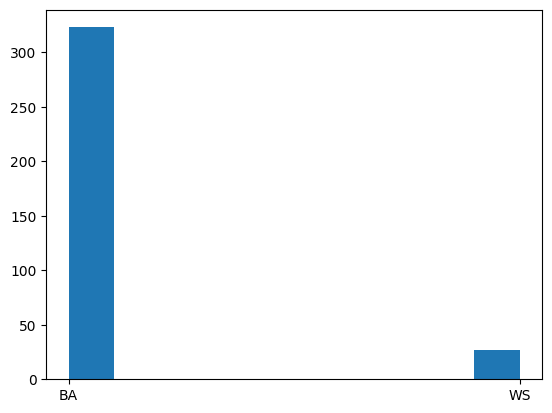

In [151]:
plt.hist(y_pred_buda)

In [152]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

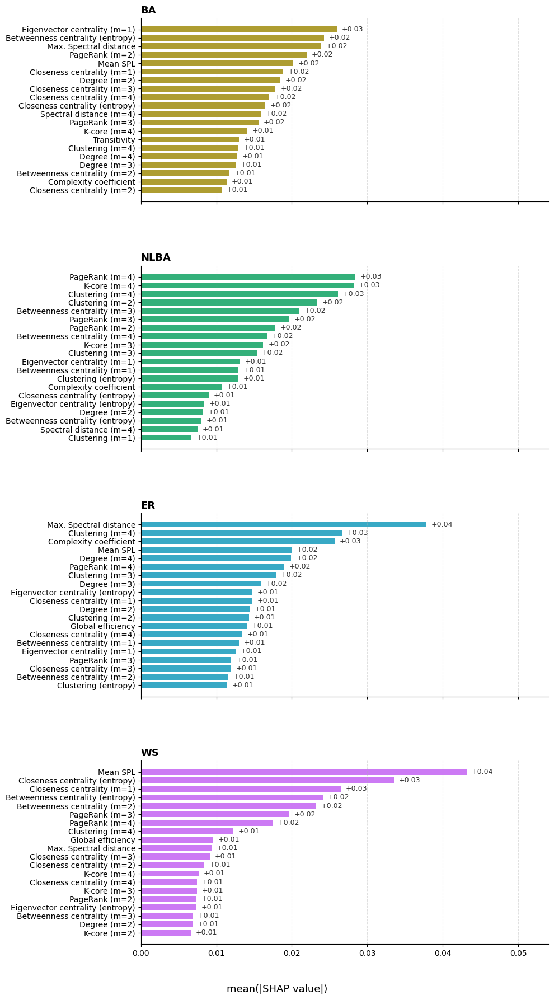

In [153]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_buda_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Displaying classification results

In [154]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,BA,BA,BA,BA
1,BA,BA,BA,BA
2,BA,BA,BA,BA
3,BA,BA,BA,BA
4,BA,BA,BA,BA
...,...,...,...,...
345,WS,BA,BA,BA
346,WS,BA,BA,BA
347,WS,BA,BA,BA
348,WS,WS,BA,BA


In [155]:
res_preds.to_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


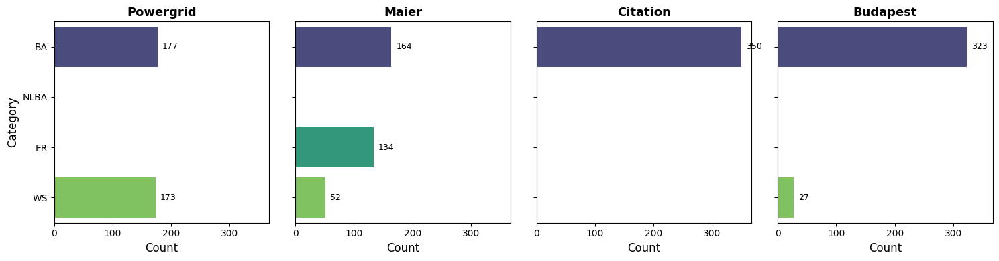

In [156]:
df = pd.read_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('results/complementary/categories_distribution_' + str(size_sample) + 'N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()

## B=75%

### Powergrid

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_pg.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [161]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [162]:
#Testing
y_pred_pg = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([ 97.,   0.,   0.,   0.,   0., 252.,   0.,   0.,   0.,   1.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

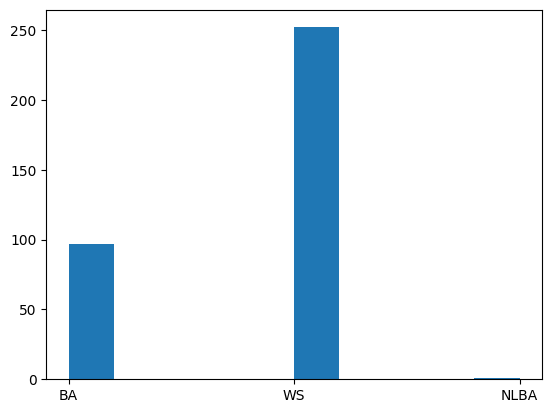

In [163]:
plt.hist(y_pred_pg)

In [164]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

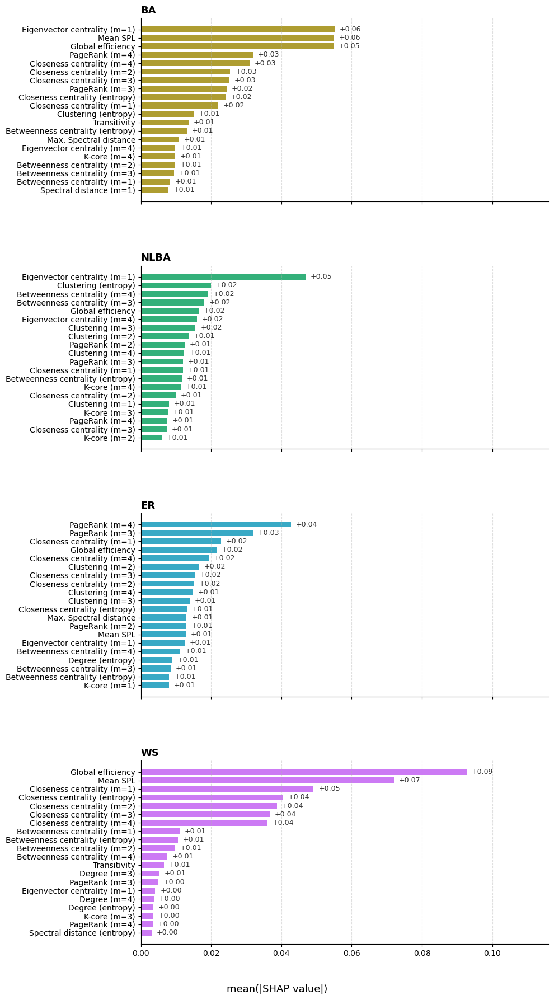

In [165]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_powergrid_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Maier

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_maier.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [169]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [170]:
#Testing
y_pred_maier = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([217.,   0.,   0.,   0.,   0., 131.,   0.,   0.,   0.,   2.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

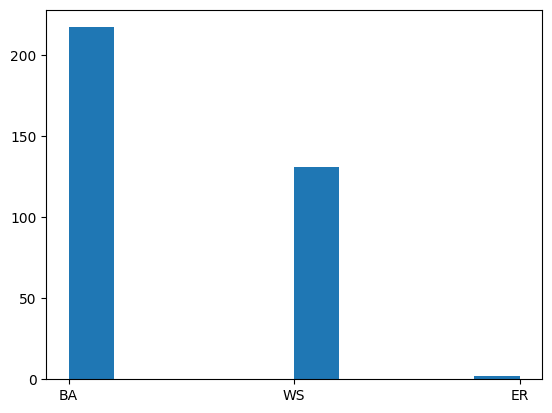

In [171]:
plt.hist(y_pred_maier)

In [172]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

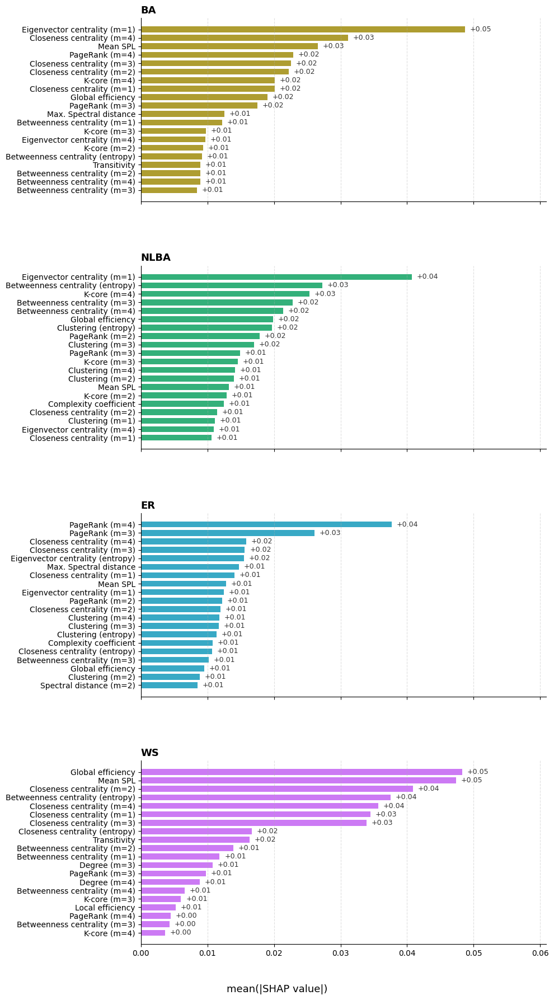

In [173]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_maier_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Citation

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_cit.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
X_test = X_test[X_train.columns]
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [176]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [177]:
#Testing
y_pred_cit = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([  0.,   0.,   0.,   0.,   0., 350.,   0.,   0.,   0.,   0.]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 <BarContainer object of 10 artists>)

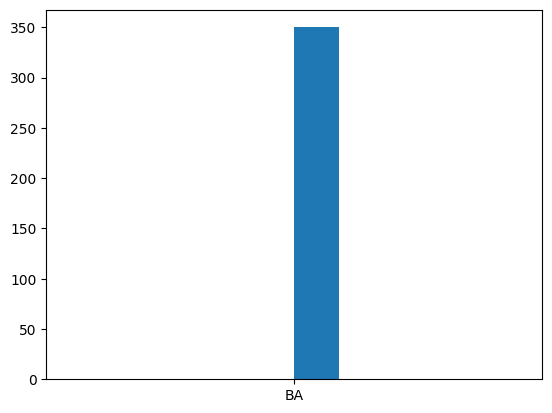

In [178]:
plt.hist(y_pred_cit)

In [179]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

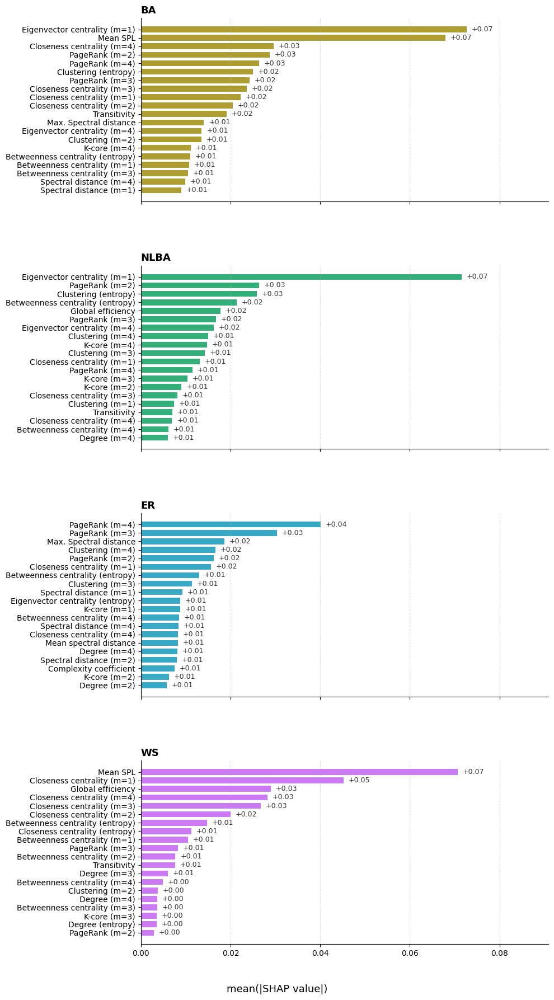

In [180]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_cit_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Budapest

In [ ]:
#Train dataset
data = pd.read_csv(path + 'full_pca_synth_networks.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == size_sample*1000)]      #so that we have constant N

X_train = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density', 'graph_type'], axis=1)
y_train = subpop_data['graph_type']

In [ ]:
#Test dataset
data = pd.read_csv(path + 'pca_buda.csv', index_col=0)

subpop_data = data[(data['sampling_method']!='Original')]
subpop_data = subpop_data[(subpop_data['sample_size'] == subpop_data.sample_size.unique()[size_sample_index])]      #so that we have constant N (40%)

X_test = subpop_data.drop(['pca_component_1', 'pca_component_2', 'pca_component_3', 'graph_id', 
                        'sampling_method', 'sample_size','sample_edges', 'net_density'], axis=1)
#And there's no correct answer.
#y = subpop_data['sampling_method']

In [184]:
#Training the model on the best parameters found
model = RandomForestClassifier(n_estimators=250, max_depth=9, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",250
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

In [185]:
#Testing
y_pred_buda = model.predict(X_test)
#print(classification_report(y_test, y_pred, target_names=y.unique()))

(array([184.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 166.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

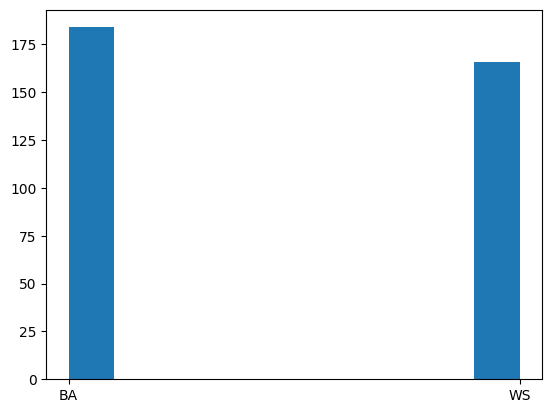

In [186]:
plt.hist(y_pred_buda)

In [187]:
#Rename columns for better readability
X_test.rename(columns=display_column_names, inplace=True)

#SHAP values & plots

shap.initjs()
# compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)     #here we use the test set since this is a transfer learning task

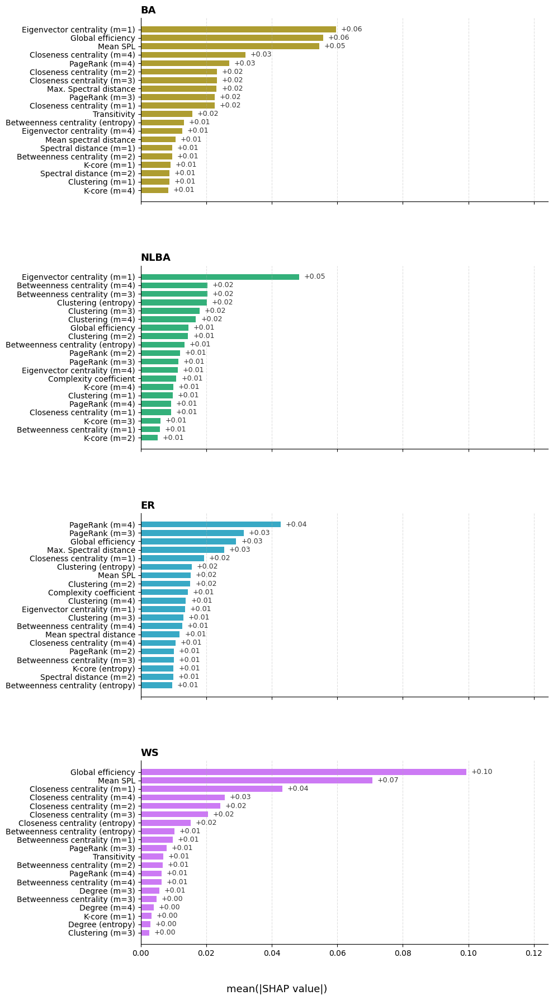

In [188]:
max_display = 20
#class_names = list(y.unique())     #base names
class_names = ['BA','NLBA','ER','WS']      #better display names
num_classes = len(class_names)

# 1. Extract feature names
if hasattr(shap_values, "feature_names") and shap_values.feature_names is not None:
    feature_names = np.array(shap_values.feature_names)
else:
    feature_names = np.array(X.columns)

# 2. Compute mean |SHAP value| matrix (num_features, num_classes) for global x-axis scaling
mean_abs_shap = np.column_stack([
    np.abs(shap_values[..., c].values).mean(axis=0)
    for c in range(num_classes)
])
global_max = mean_abs_shap.max()

# 3. Generate 'husl' palette hex colors for categories
husl_colors = sns.color_palette("husl", num_classes+1).as_hex()

# 4. Build vertical subplot grid with independent y-axes (sharey=False)
fig, axes = plt.subplots(
    num_classes, 1, 
    figsize=(10, 4.5 * num_classes), 
    sharex=True, 
    sharey=False  # Allows unique feature order and labels per subplot
)

if num_classes == 1:
    axes = [axes]

# 5. Plot each class with its own class-specific top-N feature ranking
for c, class_name in enumerate(class_names):
    ax = axes[c]
    
    # Extract and rank features strictly for this class
    class_shap = mean_abs_shap[:, c]
    top_indices = np.argsort(class_shap)[-max_display:]  # Top features ascending
    
    class_features = feature_names[top_indices]
    class_values = class_shap[top_indices]
    
    y_pos = np.arange(len(class_features))
    
    bars = ax.barh(y_pos, class_values, color=husl_colors[c+1], height=0.7)
    
    # Annotate bar values
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (global_max * 0.015), 
            bar.get_y() + bar.get_height() / 2, 
            f"+{width:.2f}", 
            va='center', 
            ha='left', 
            fontsize=9, 
            color='#333333'
        )

    ax.set_title(f"{class_name}", fontsize=13, loc='left', pad=6, fontweight='bold')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(class_features, fontsize=10)  # Render class-specific feature names
    
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Maintain identical x-axis limit across all subplots
axes[0].set_xlim(0, global_max * 1.25)

# Single centered X-axis label
fig.supxlabel("mean(|SHAP value|)", fontsize=13, y=0.01)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35, bottom=0.06)
plt.savefig('shap_categories_buda_' + str(size_sample) + 'N.pdf', format='pdf')
plt.show()

### Displaying classification results

In [189]:
res_preds = pd.DataFrame(data={'Powergrid': y_pred_pg, 'Maier': y_pred_maier, 'Citation': y_pred_cit, 'Budapest': y_pred_buda})
res_preds

,Powergrid,Maier,Citation,Budapest
0,BA,BA,BA,BA
1,BA,BA,BA,BA
2,BA,BA,BA,BA
3,BA,BA,BA,BA
4,BA,BA,BA,BA
...,...,...,...,...
345,WS,BA,BA,BA
346,WS,BA,BA,BA
347,WS,BA,BA,WS
348,WS,BA,BA,BA


In [190]:
res_preds.to_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_746859/2047499369.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


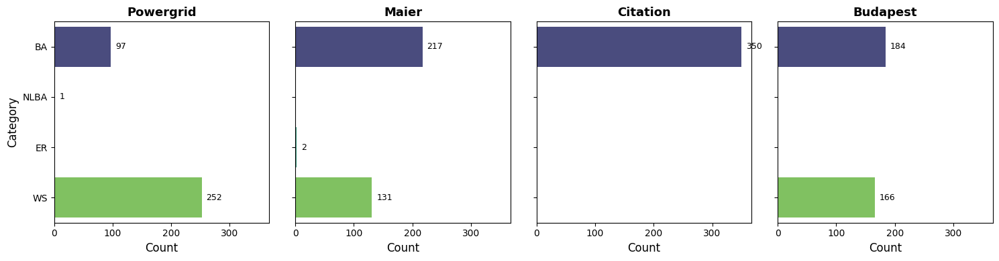

In [191]:
df = pd.read_csv('results/complementary/y_test_predicts_real_nets' + str(size_sample) + '.csv')

cols = ['Powergrid', 'Maier', 'Citation', 'Budapest']
categories = ['BA', 'NLBA', 'ER', 'WS']

#sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, sharex=True)


for ax, col in zip(axes, cols):
    sns.countplot(
        data=df,
        y=col,
        order=categories,
        ax=ax,
        palette="viridis"
    )
    
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', fontsize=12)
    ax.set_ylabel('Category' if ax == axes[0] else '', fontsize=12)

    #Display numerical labels on each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=9
            )

plt.tight_layout()
plt.savefig('results/complementary/categories_distribution_' + str(size_sample) + 'N.pdf', dpi=300, bbox_inches='tight', format='pdf')
plt.show()